# Q2 — Edge-Based Analysis and Local Feature Extraction
**Course:** Computer Vision Lab (AI441L) &nbsp;·&nbsp; **Name:** Hamza &nbsp;·&nbsp; **Reg. No.:** ____________ &nbsp;·&nbsp; **Marks:** 20 [(CLO-2, GA-4) P4]

**Objective.** Build one analysis pipeline — Gaussian smoothing → Canny / Sobel / Laplacian edges → HOG → SIFT — on a single real-world image, measure every output, and judge which method suits which job.

| Part | What is produced in this notebook |
|---|---|
| **A** Canny (6) | smoothing justification with a noise estimate, Canny for 4 threshold pairs, Sobel / Laplacian / LoG / Canny comparison (continuity, thickness, noise), edge-density table + parameter sweeps |
| **B** HOG (5) | HOG written from first principles (checked against OpenCV), visualisation, dimension derivation, illumination test, cell-size and bin sweeps |
| **C** SIFT (5) | keypoints with scale/orientation, descriptor dimensions, matching against a rotated + scaled copy with ground-truth accuracy, rotation/scale sweep, failure case |
| **D** Judgement (4) | comparison table with measured cost, recommendations backed by the experiments |

**How to run (Google Colab):** *Runtime → Run all.* When the loading cell asks, upload the collage image (any file name works). Every tunable value is in the **Config** cell, so a parameter the examiner asks about can be changed in one place and the notebook re-run.

> All numbers quoted in the written analysis come from the reference run (OpenCV 5.0, NumPy 2.5). Another OpenCV build (e.g. Colab's 4.x) can shift SIFT counts slightly; the **Evidence summary** cell at the end prints the live values for your run.

## 0. Setup
Only the permitted libraries are used: Python, OpenCV, NumPy, Matplotlib and SciPy (`scipy.ndimage.gaussian_laplace` for the Laplacian-of-Gaussian).

In [ ]:
import os, time, math
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage

plt.rcParams.update({
    "figure.dpi": 72, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
    "figure.titlesize": 13, "figure.titleweight": "bold", "figure.constrained_layout.use": True,
})
# Fixed categorical colour order (colour-blind-safe set), used consistently in every chart
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

print("Python  :", os.sys.version.split()[0])
print("OpenCV  :", cv2.__version__)
print("NumPy   :", np.__version__)
import scipy, matplotlib
print("SciPy   :", scipy.__version__)
print("Matplot :", matplotlib.__version__)
assert hasattr(cv2, "SIFT_create"), "OpenCV >= 4.4 is required for SIFT (Colab already has it)."

Python  : 3.13.16
OpenCV  : 5.0.0
NumPy   : 2.5.3
SciPy   : 1.18.1
Matplot : 3.11.2


### Configuration — all parameters in one place
Comparisons in this notebook are *controlled*: each experiment changes only the parameter under study and reads everything else from this cell.

In [ ]:
# ===================== ALL EXPERIMENT PARAMETERS (edit here) =====================
IMG_PATH       = "messi_collage.png"   # the uploaded collage image

# --- Part A : smoothing + Canny ---
GAUSS_KSIZE    = (5, 5)        # Gaussian kernel size (must be odd)
GAUSS_SIGMA    = 1.4           # Gaussian std-dev in pixels (classic Canny choice)
CANNY_APERTURE = 3             # Sobel aperture used inside Canny (held fixed)
CANNY_L2       = True          # exact magnitude sqrt(gx^2+gy^2) instead of |gx|+|gy| (held fixed)
CANNY_PAIRS    = [(20, 60), (50, 150), (100, 200), (150, 300)]   # (low, high) thresholds
REF_PAIR       = (50, 150)     # reference setting used for the method comparison
SOBEL_KSIZE    = 3
LAPLACE_KSIZE  = 3
LOG_SIGMA      = GAUSS_SIGMA   # LoG scale = same smoothing as the other detectors (controlled)
LOG_ZC_T       = 3.0           # minimum slope across a LoG zero-crossing (suppresses flat-area noise)
NOISE_SIGMA    = 20            # std-dev of additive Gaussian noise for the robustness test
SEED           = 42

# --- Part B : HOG ---
HOG_ROI        = (112, 256, 512, 640)   # (x, y, w, h): central subject - face, hands, trophy, jersey
HOG_CELL       = 8             # pixels per cell (square)
HOG_BLOCK      = 2             # cells per block side (2x2 cells = 16x16 px)
HOG_BINS       = 9             # unsigned orientation bins over 0-180 deg (20 deg each)
HOG_CLIP       = 0.2           # L2-Hys clipping value

# --- Part C : SIFT ---
SIFT_PARAMS    = dict(nfeatures=0, nOctaveLayers=3, contrastThreshold=0.04,
                      edgeThreshold=10, sigma=1.6)   # Lowe (2004) defaults
RATIO          = 0.75          # Lowe ratio-test threshold
TF_ANGLE       = 30            # rotation (degrees, counter-clockwise) for the transformed copy
TF_SCALE       = 0.75          # isotropic scale for the transformed copy
RANSAC_THR     = 3.0           # px, RANSAC reprojection threshold
GT_TOL         = 3.0           # px, a match is "correct" if it lands within this distance of the truth
# ===================================================================================
EVID = {}   # collects every number quoted in the written analysis

## 1. Image and its documentation

| Property | Value |
|---|---|
| **Source** | Fan-made photo collage of footballer Lionel Messi (FC Barcelona and Argentina kits, World Cup trophy), provided by the student as the task image. Original creator unknown — *add the download URL here if you have it.* |
| **File / dimensions** | PNG, **736 × 1308 px** (W × H), 4 channels |
| **Colour space** | sRGB stored as **BGRA** by OpenCV; alpha = 255 everywhere (fully opaque) |
| **Data type** | `uint8`, range 0–255 |
| **Preprocessing** | alpha composited over white (a no-op here), BGR→RGB for display, BGR→**grayscale** (ITU-R BT.601: $Y = 0.299R + 0.587G + 0.114B$) for all analysis; **no resizing**. Smoothing is applied only where a part says so. |

**Why this image fits the scenario.** It contains *multiple boundaries* (collage seams, people, the trophy, the jersey number), *strong texture* (striped kits, tattoos, the trophy's relief, crowd), *uneven illumination* (dark top-left, brightly lit centre) and *repeated objects* (the "QATAR AIRWAYS" sponsor appears twice, several club crests, two "MESSI 10" shirts) — which later stresses SIFT's distinctiveness.

IMAGE DOCUMENTATION
------------------------------------------------------------
File               : messi_collage.png  (2028 KB)
Source             : collage photo supplied by the student (see markdown above)
Loaded array       : shape=(1308, 736, 4), dtype=uint8, range=[0, 255]
Colour space loaded: BGRA (OpenCV channel order), alpha min=255 max=255
Display copy       : RGB, shape=(1308, 736, 3), dtype=uint8
Working copy       : grayscale (BT.601 luma), shape=(1308, 736), dtype=uint8
Width x Height     : 736 x 1308 px  (962,688 pixels)
Gray statistics    : mean=76.9, std=62.2, min=0, max=255
Preprocessing      : alpha composited over white -> BGR->RGB (display) and BGR->Gray (analysis);
                     no resizing; per-part smoothing is described in each part.


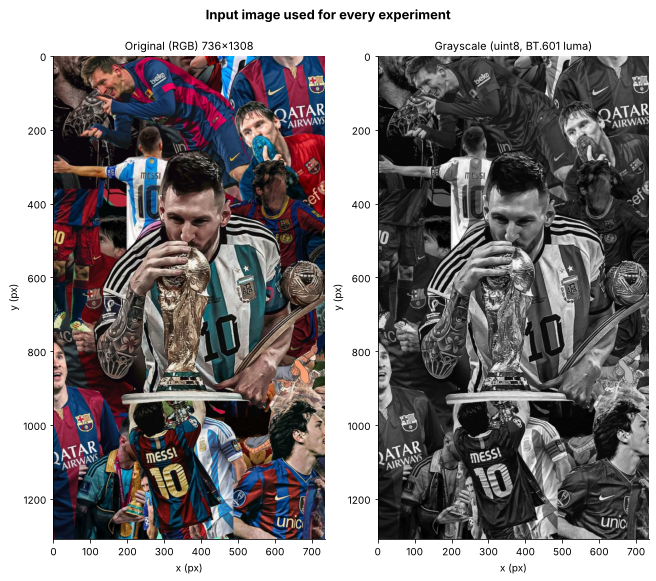

In [ ]:
# ---- Load the image (works locally or in Colab: if the file is missing, Colab asks you to upload it)
if not os.path.exists(IMG_PATH):
    try:
        from google.colab import files
        print(f"'{IMG_PATH}' not found - please upload the collage image.")
        uploaded = files.upload()
        IMG_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"Put the image next to this notebook as '{IMG_PATH}'.")

raw = cv2.imread(IMG_PATH, cv2.IMREAD_UNCHANGED)
assert raw is not None, "OpenCV could not read the image."

if raw.ndim == 3 and raw.shape[2] == 4:            # PNG with alpha channel (BGRA)
    alpha = raw[:, :, 3]
    loaded_space = "BGRA (OpenCV channel order), alpha min=%d max=%d" % (alpha.min(), alpha.max())
    # composite over white in case any pixels are transparent; alpha=255 everywhere -> unchanged
    a = alpha[..., None].astype(np.float32) / 255.0
    bgr = (raw[:, :, :3].astype(np.float32) * a + 255.0 * (1 - a)).round().astype(np.uint8)
elif raw.ndim == 3:
    loaded_space, bgr = "BGR (OpenCV channel order)", raw
else:
    loaded_space, bgr = "single-channel grayscale", cv2.cvtColor(raw, cv2.COLOR_GRAY2BGR)

rgb  = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)        # for display with Matplotlib
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)       # Y = 0.299 R + 0.587 G + 0.114 B  (ITU-R BT.601)
H, W = gray.shape

print("IMAGE DOCUMENTATION")
print("-" * 60)
print(f"File               : {IMG_PATH}  ({os.path.getsize(IMG_PATH)/1024:.0f} KB)")
print(f"Source             : collage photo supplied by the student (see markdown above)")
print(f"Loaded array       : shape={raw.shape}, dtype={raw.dtype}, range=[{raw.min()}, {raw.max()}]")
print(f"Colour space loaded: {loaded_space}")
print(f"Display copy       : RGB, shape={rgb.shape}, dtype={rgb.dtype}")
print(f"Working copy       : grayscale (BT.601 luma), shape={gray.shape}, dtype={gray.dtype}")
print(f"Width x Height     : {W} x {H} px  ({W*H:,} pixels)")
print(f"Gray statistics    : mean={gray.mean():.1f}, std={gray.std():.1f}, min={gray.min()}, max={gray.max()}")
print("Preprocessing      : alpha composited over white -> BGR->RGB (display) and BGR->Gray (analysis);")
print("                     no resizing; per-part smoothing is described in each part.")

fig, ax = plt.subplots(1, 2, figsize=(9, 8))
ax[0].imshow(rgb); ax[0].set_title(f"Original (RGB) {W}x{H}")
ax[1].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Grayscale (uint8, BT.601 luma)")
for a_ in ax: a_.set_xlabel("x (px)"); a_.set_ylabel("y (px)")
fig.suptitle("Input image used for every experiment"); plt.show()

### Helper functions
* **`edge_metrics`** — density $D = N_{edge}/(H W)$; *continuity* through 8-connected components (fewer, larger components and fewer fragments under 10 px = more continuous); *thickness* = edge pixels ÷ pixels after Zhang–Suen thinning (1.0 means perfectly 1-px-wide edges).
* **`zero_crossings`** — Marr–Hildreth edges: a pixel whose Laplacian changes sign against its right/lower neighbour with a jump larger than a slope threshold.
* **`tolerant_f1`** — precision/recall between two edge maps after dilating by a tolerance (used for edge repeatability).

In [ ]:
# ---------------------------- helper functions ----------------------------
def print_table(headers, rows, title=None):
    def f(v):
        if isinstance(v, float):
            return f"{v:.4f}" if abs(v) < 10 else f"{v:,.2f}"
        if isinstance(v, (int, np.integer)):
            return f"{v:,}"
        return str(v)
    body = [[f(v) for v in r] for r in rows]
    widths = [max(len(str(h)), *(len(r[i]) for r in body)) for i, h in enumerate(headers)]
    line = "+".join("-" * (w + 2) for w in widths)
    if title: print(title)
    print(" | ".join(str(h).ljust(w) for h, w in zip(headers, widths)))
    print(line)
    for r in body:
        print(" | ".join(c.rjust(w) for c, w in zip(r, widths)))
    print()

def zhang_suen_thin(binary):
    """Zhang-Suen (1984) morphological thinning -> 1-pixel-wide skeleton (vectorised NumPy)."""
    img = np.pad((binary > 0).astype(np.uint8), 1)
    changed = True
    while changed:
        changed = False
        for step in (0, 1):
            P = img
            p2, p3, p4 = P[:-2, 1:-1], P[:-2, 2:], P[1:-1, 2:]
            p5, p6, p7 = P[2:, 2:], P[2:, 1:-1], P[2:, :-2]
            p8, p9 = P[1:-1, :-2], P[:-2, :-2]
            nb = [p2, p3, p4, p5, p6, p7, p8, p9]
            B = sum(n.astype(np.int32) for n in nb)                       # number of neighbours
            seq = nb + [p2]
            A = sum(((seq[i] == 0) & (seq[i + 1] == 1)).astype(np.int32) for i in range(8))  # 0->1 transitions
            if step == 0:
                cond = ((p2 * p4 * p6) == 0) & ((p4 * p6 * p8) == 0)
            else:
                cond = ((p2 * p4 * p8) == 0) & ((p2 * p6 * p8) == 0)
            m = (P[1:-1, 1:-1] == 1) & (B >= 2) & (B <= 6) & (A == 1) & cond
            if m.any():
                img[1:-1, 1:-1][m] = 0
                changed = True
    return img[1:-1, 1:-1]

def edge_metrics(binary):
    """Density, continuity (connected components) and thickness of a binary edge map."""
    b = (binary > 0).astype(np.uint8)
    n = int(b.sum())
    ncc, _, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    sizes = stats[1:, cv2.CC_STAT_AREA]
    skel = int(zhang_suen_thin(b).sum())
    return dict(pixels=n, density=n / b.size, components=int(ncc - 1),
                mean_len=float(sizes.mean()) if len(sizes) else 0.0,
                short_frac=float((sizes < 10).mean()) if len(sizes) else 0.0,
                thickness=n / max(skel, 1))

def tolerant_f1(ref, test, tol=1):
    """Precision/recall/F1 between two edge maps allowing `tol` px of localisation error."""
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    r, t = (ref > 0).astype(np.uint8), (test > 0).astype(np.uint8)
    rd, td = cv2.dilate(r, k), cv2.dilate(t, k)
    p = (t & rd).sum() / max(t.sum(), 1)
    rc = (r & td).sum() / max(r.sum(), 1)
    return p, rc, 2 * p * rc / max(p + rc, 1e-12)

def zero_crossings(L, thresh):
    """Pixels where L changes sign to its right/lower neighbour with a slope larger than thresh."""
    zc = np.zeros(L.shape, bool)
    h = (np.sign(L[:, :-1]) * np.sign(L[:, 1:]) < 0) & (np.abs(L[:, :-1] - L[:, 1:]) > thresh)
    v = (np.sign(L[:-1, :]) * np.sign(L[1:, :]) < 0) & (np.abs(L[:-1, :] - L[1:, :]) > thresh)
    zc[:, :-1] |= h
    zc[:-1, :] |= v
    return zc.astype(np.uint8) * 255

def canny(img, low, high):
    return cv2.Canny(img, low, high, apertureSize=CANNY_APERTURE, L2gradient=CANNY_L2)

def show_grid(images, titles, suptitle, ncols, figsize, cmap="gray", crop=None):
    nrows = math.ceil(len(images) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    for ax, im, t in zip(axes.ravel(), images, titles):
        if crop is not None:
            x, y, w, h = crop; im = im[y:y + h, x:x + w]
        ax.imshow(im, cmap=cmap) if im.ndim == 2 else ax.imshow(im)
        ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
    for ax in axes.ravel()[len(images):]: ax.axis("off")
    fig.suptitle(suptitle); plt.show()

ZOOM = (380, 560, 240, 300)   # (x, y, w, h): jersey number "10", hand, trophy - used for zoomed views
print("Helpers ready.")

Helpers ready.


---
# Part A — Canny Edge Detection and Parameter Sensitivity

## A1. Grayscale + Gaussian smoothing — and why smoothing comes first (1)

The 2-D Gaussian
$$G_\sigma(x,y)=\frac{1}{2\pi\sigma^2}\exp\!\left(-\frac{x^2+y^2}{2\sigma^2}\right)$$
is separable, $G_\sigma(x,y)=g_\sigma(x)\,g_\sigma(y)$, so OpenCV applies a 1-D kernel along rows and then columns.

**Why smoothing precedes edge detection.**
1. *Differentiation amplifies noise.* Every edge detector estimates a derivative. In the frequency domain $\mathcal F\{\partial I/\partial x\} = j\omega\,\hat I(\omega)$: each component is multiplied by its frequency, so high-frequency noise (sensor noise, JPEG artefacts, fine fabric texture) is boosted the most. The Gaussian is a low-pass filter, $\hat G(\omega)=e^{-\sigma^2\omega^2/2}$, which removes those frequencies *before* they are amplified.
2. *Smoothing then differentiating is one optimal operator.* By the derivative theorem of convolution, $\nabla(G_\sigma * I) = (\nabla G_\sigma) * I$ — a derivative-of-Gaussian filter, which Canny showed is close to optimal for step edges (good detection, good localisation, one response per edge).
3. *OpenCV's `cv2.Canny` does **not** smooth internally* — it starts directly with Sobel derivatives — so the smoothing step has to be done explicitly.

**Parameter choice.** $\sigma = 1.4$ with a $5\times5$ kernel is the classical Canny setting: strong enough to suppress pixel-level noise while blurring edges by only about one pixel. A larger $\sigma$ removes more texture but rounds corners and merges nearby edges (measured in A4).

**Evidence measured below:** a noise estimate (Immerkær's method, which convolves with a Laplacian-difference mask that cancels image structure), Canny on raw vs smoothed input with identical thresholds, and a 1-D intensity profile with its derivative.

1-D Gaussian weights (ksize=5, sigma=1.4): [0.1102 0.2369 0.3058 0.2369 0.1102]  sum = 1.0
2-D kernel = outer product g g^T (all 25 weights sum to 1):
 [[0.0121 0.0261 0.0337 0.0261 0.0121]
 [0.0261 0.0561 0.0724 0.0561 0.0261]
 [0.0337 0.0724 0.0935 0.0724 0.0337]
 [0.0261 0.0561 0.0724 0.0561 0.0261]
 [0.0121 0.0261 0.0337 0.0261 0.0121]]


Effect of smoothing on Canny (thresholds fixed at (50, 150))
input to Canny    | noise sigma (Immerkaer) | edge pixels | density | components | fragments <10px
-------------------+-------------------------+-------------+---------+------------+-----------------
         raw gray |                  2.9390 |     154,547 |  0.1605 |      3,406 |           47.5%
Gaussian-smoothed |                  0.3547 |      85,971 |  0.0893 |      1,001 |            6.6%



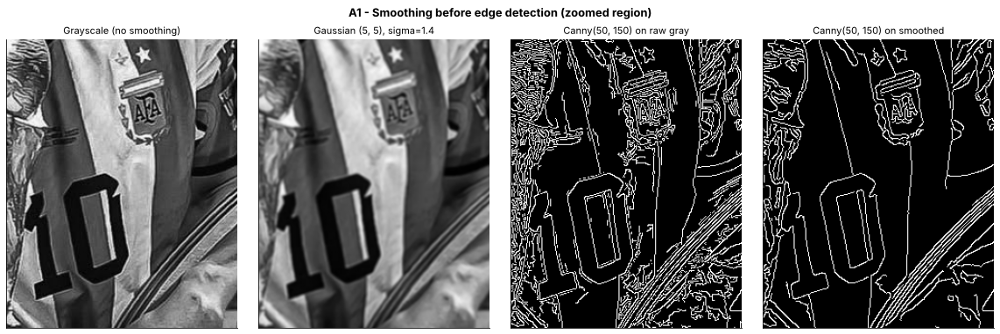

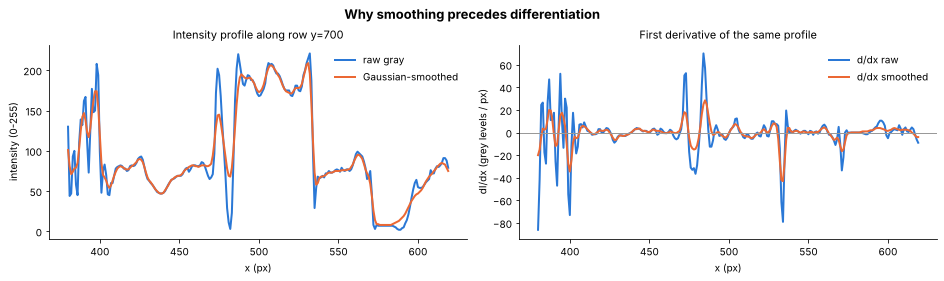

In [ ]:
# ---------------- A1: grayscale -> Gaussian smoothing ----------------
blur = cv2.GaussianBlur(gray, GAUSS_KSIZE, GAUSS_SIGMA)

g1 = cv2.getGaussianKernel(GAUSS_KSIZE[0], GAUSS_SIGMA)     # separable: G(x,y) = g(x) g(y)
G2 = g1 @ g1.T
np.set_printoptions(precision=4, suppress=True)
print(f"1-D Gaussian weights (ksize={GAUSS_KSIZE[0]}, sigma={GAUSS_SIGMA}):", g1.ravel(), " sum =", g1.sum().round(6))
print("2-D kernel = outer product g g^T (all 25 weights sum to 1):\n", G2)

def noise_sigma(img):
    """Immerkaer (1996) fast noise estimate: sigma_n = sqrt(pi/2) / (6 (W-2)(H-2)) * sum |I * N|."""
    N = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)
    conv = cv2.filter2D(img.astype(np.float64), -1, N)[1:-1, 1:-1]
    h, w = img.shape
    return math.sqrt(math.pi / 2) * np.abs(conv).sum() / (6 * (w - 2) * (h - 2))

ns_raw, ns_blur = noise_sigma(gray), noise_sigma(blur)
e_raw, e_blur = canny(gray, *REF_PAIR), canny(blur, *REF_PAIR)
m_raw, m_blur = edge_metrics(e_raw), edge_metrics(e_blur)
EVID.update(ns_raw=ns_raw, ns_blur=ns_blur, a1_raw=m_raw, a1_blur=m_blur)

print_table(["input to Canny", "noise sigma (Immerkaer)", "edge pixels", "density", "components", "fragments <10px"],
            [["raw gray", ns_raw, m_raw["pixels"], m_raw["density"], m_raw["components"], f'{m_raw["short_frac"]:.1%}'],
             ["Gaussian-smoothed", ns_blur, m_blur["pixels"], m_blur["density"], m_blur["components"], f'{m_blur["short_frac"]:.1%}']],
            title=f"Effect of smoothing on Canny (thresholds fixed at {REF_PAIR})")

show_grid([gray, blur, e_raw, e_blur],
          ["Grayscale (no smoothing)", f"Gaussian {GAUSS_KSIZE}, sigma={GAUSS_SIGMA}",
           f"Canny{REF_PAIR} on raw gray", f"Canny{REF_PAIR} on smoothed"],
          "A1 - Smoothing before edge detection (zoomed region)", 4, (16, 5.2), crop=ZOOM)

# 1-D view: a derivative amplifies high-frequency noise; smoothing first suppresses it
row = 700
xs = np.arange(380, 620)
noisy_row = gray.astype(float)[row, xs]
smooth_row = blur.astype(float)[row, xs]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(xs, noisy_row, color=C[0], label="raw gray")
ax[0].plot(xs, smooth_row, color=C[1], label="Gaussian-smoothed")
ax[0].set(title=f"Intensity profile along row y={row}", xlabel="x (px)", ylabel="intensity (0-255)"); ax[0].legend()
ax[1].plot(xs, np.gradient(noisy_row), color=C[0], label="d/dx raw")
ax[1].plot(xs, np.gradient(smooth_row), color=C[1], label="d/dx smoothed")
ax[1].axhline(0, color="#999", lw=1)
ax[1].set(title="First derivative of the same profile", xlabel="x (px)", ylabel="dI/dx (grey levels / px)"); ax[1].legend()
fig.suptitle("Why smoothing precedes differentiation"); plt.show()

**A1 result.** Smoothing reduced the estimated noise standard deviation from **2.94 to 0.35 grey levels**. With identical thresholds (50, 150), Canny on the *raw* image returned 154,547 edge pixels in 3,406 pieces, **47.5 %** of them fragments shorter than 10 px. On the *smoothed* image it returned 85,971 pixels in 1,001 pieces with only **6.6 %** fragments. The zoomed panels show the cause: without smoothing, the shirt's fabric weave and the crest's embroidery turn into short spurious edges. The 1-D plot shows the mechanism — the raw derivative has many spikes of ±50 that do not correspond to real boundaries, while the smoothed derivative keeps only the true steps (for example the stripe boundaries near x ≈ 475 and 530).

## A2. Canny with several threshold pairs (2)

**How Canny works.** On the smoothed image $I_s$:
1. **Gradient** with 3×3 Sobel: $M=\sqrt{g_x^2+g_y^2}$ (with `L2gradient=True`; `False` would use $|g_x|+|g_y|$), $\theta=\operatorname{atan2}(g_y,g_x)$.
2. **Non-maximum suppression (NMS)** — $\theta$ is quantised to 0°/45°/90°/135°, and a pixel survives only if $M$ is at least its two neighbours across the edge. This thins ridges to one pixel.
3. **Double threshold** — $M\ge T_{high}$ → *strong*; $T_{low}\le M<T_{high}$ → *weak*; $M<T_{low}$ → discarded.
4. **Hysteresis** — a weak pixel is kept only if it is 8-connected (directly or through other weak pixels) to a strong pixel. Strong pixels *seed* contours; the low threshold decides how far a contour may continue through fainter sections.

**What the numbers mean.** A 3×3 Sobel responds with $4h$ to a sharp step of height $h$, and after σ = 1.4 smoothing with about $2.17h$ (measured in A3). So $T_{high}=150$ on the smoothed image corresponds to a step of roughly **69 grey levels**.

**Pairs tested** (Canny recommends low : high between 1:2 and 1:3): **(20, 60)** permissive, **(50, 150)** reference, **(100, 200)** stricter, **(150, 300)** very strict. Held constant: the same smoothed input, Sobel aperture = 3, `L2gradient=True`.

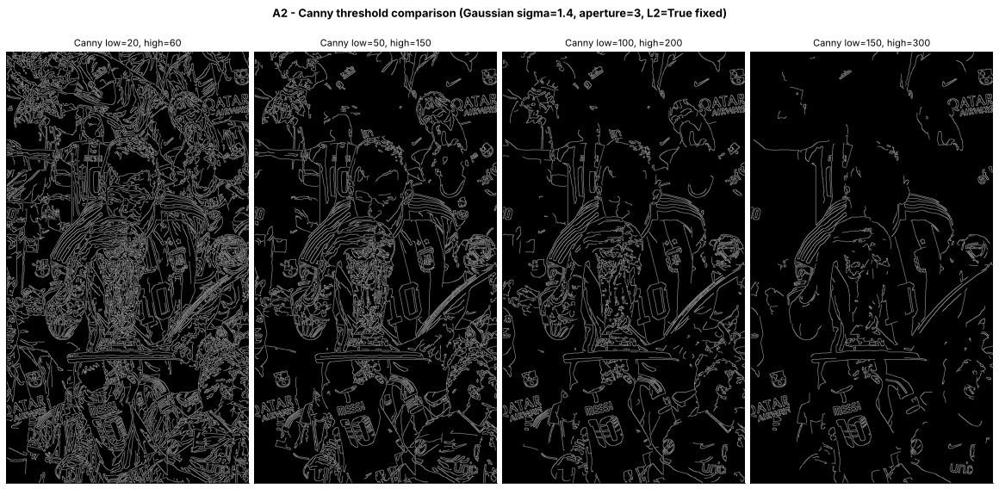

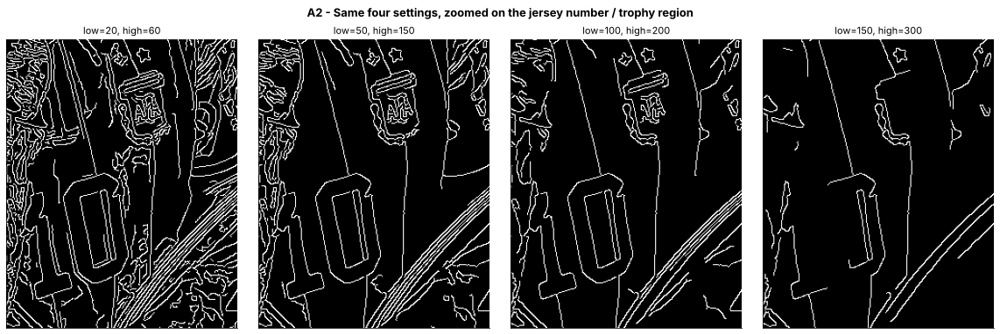

In [ ]:
# ---------------- A2: Canny with several (low, high) threshold pairs ----------------
canny_maps = {p: canny(blur, *p) for p in CANNY_PAIRS}   # same smoothed input, aperture, L2 for all
show_grid([canny_maps[p] for p in CANNY_PAIRS],
          [f"Canny low={p[0]}, high={p[1]}" for p in CANNY_PAIRS],
          f"A2 - Canny threshold comparison (Gaussian sigma={GAUSS_SIGMA}, aperture={CANNY_APERTURE}, L2={CANNY_L2} fixed)",
          4, (16, 8.2))
show_grid([canny_maps[p] for p in CANNY_PAIRS],
          [f"low={p[0]}, high={p[1]}" for p in CANNY_PAIRS],
          "A2 - Same four settings, zoomed on the jersey number / trophy region", 4, (16, 5.2), crop=ZOOM)

**A2 result** (numbers from the A4 table).
* **(20, 60)** — 15.3 % of the image is marked as edge, 3,103 components, 31.7 % fragments. Every fold, tattoo line and trophy highlight appears; texture dominates and object outlines are buried.
* **(50, 150)** — 8.9 %. Outlines of the face, hands, trophy, the "10" and the AFA crest are closed and continuous; most fabric texture is gone. *Chosen as the reference.*
* **(100, 200)** — 6.0 %. Clean, but lower-contrast contours start to break: the jersey-stripe boundary develops gaps and the crest's inner detail is lost.
* **(150, 300)** — 3.3 %, no fragments under 10 px. Only the highest-contrast structure survives (collage seams, the sleeve stripes, parts of the trophy). Even the jersey number's outline breaks apart and the AFA crest disappears.

Raising **high** removes *seeds*, so entire weak contours disappear. Raising **low** cuts the *continuation* of contours, so they develop gaps. Both effects are separated in the A4 sweeps.

## A3. Canny vs Sobel vs Laplacian on the same image (2)

All three use the **same smoothed image** (σ = 1.4).

* **Sobel** (first derivative, smoothing in the perpendicular direction):
$K_x=\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix},\;K_y=K_x^{\!\top}$, giving magnitude $\sqrt{g_x^2+g_y^2}$ **and** direction. To compare with a binary detector, it is thresholded at $T=150$ — the *same* high threshold Canny uses on the *same* Sobel magnitude. The difference between the two maps is therefore exactly what NMS and hysteresis contribute.
* **Laplacian** (second derivative, isotropic): $\nabla^2 I=\partial^2_x I+\partial^2_y I$. OpenCV's `ksize=3` kernel is $\begin{bmatrix}2&0&2\\0&-8&0\\2&0&2\end{bmatrix}$. An edge is a **zero-crossing** of $\nabla^2 I$ (the inflection point of the intensity ramp), not a maximum. Using $\nabla^2(G_\sigma*I)=(\nabla^2G_\sigma)*I$ gives the **Laplacian-of-Gaussian** (Marr–Hildreth), computed with SciPy at σ = 1.4. Zero-crossings are kept when the jump across them exceeds 3.0, which removes crossings in nearly flat regions.

**Noise test.** (1) Each operator is applied to pure Gaussian noise and to an ideal step, giving an edge signal-to-noise ratio. (2) Noise with σ = 20 is added to the real image and the identical pipeline is re-run; the measure is *false edges in previously edge-free areas* (more than 3 px from any clean-image edge).

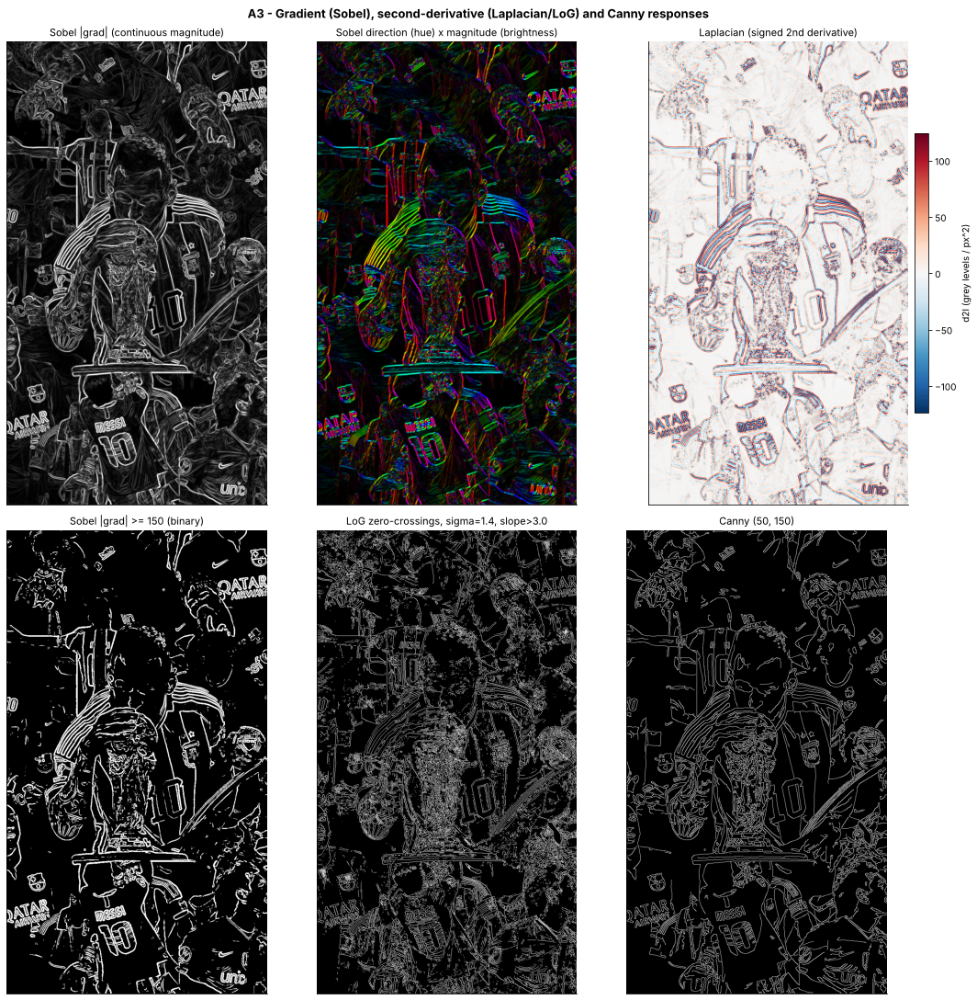

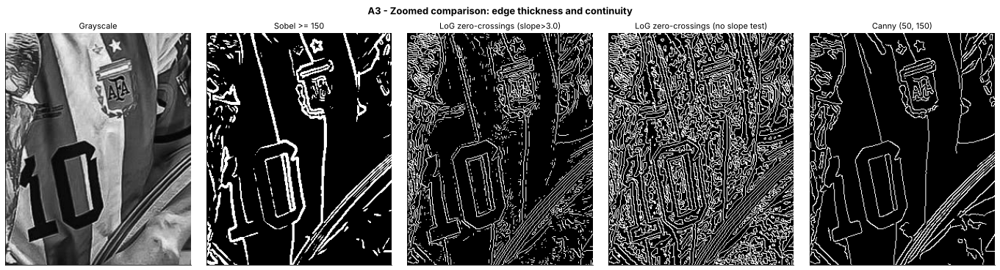

Continuity and thickness on the clean image
method              | edge px | density | components | mean comp. size (px) | fragments <10px | thickness (px/skeleton px)
---------------------+---------+---------+------------+----------------------+-----------------+----------------------------
Sobel (thresholded) | 120,239 |  0.1249 |      1,838 |                65.42 |           48.5% |                     2.6311
 LoG zero-crossings | 139,742 |  0.1452 |      8,987 |                15.55 |           78.4% |                     1.0304
    Canny (50, 150) |  85,971 |  0.0893 |      1,001 |                85.89 |            6.6% |                     1.0452

Noise amplification (noise sigma = 20); Canny uses the Sobel gradient internally
operator               | Gaussian first | peak response to 100-level step | std of response to noise | edge SNR
------------------------+----------------+---------------------------------+--------------------------+----------
Sobel |grad| (ksize 3) |       

Real image + Gaussian noise (sigma=20), identical parameters
method              | density clean | density noisy | change | false edges in edge-free areas | fragments <10px
---------------------+---------------+---------------+--------+--------------------------------+-----------------
Sobel (thresholded) |        0.1249 |        0.1253 |  +0.3% |                          0.12% |  48.5% -> 53.3%
 LoG zero-crossings |        0.1452 |        0.2450 | +68.8% |                         18.64% |  78.4% -> 83.9%
    Canny (50, 150) |        0.0893 |        0.0927 |  +3.8% |                          0.95% |    6.6% -> 5.7%



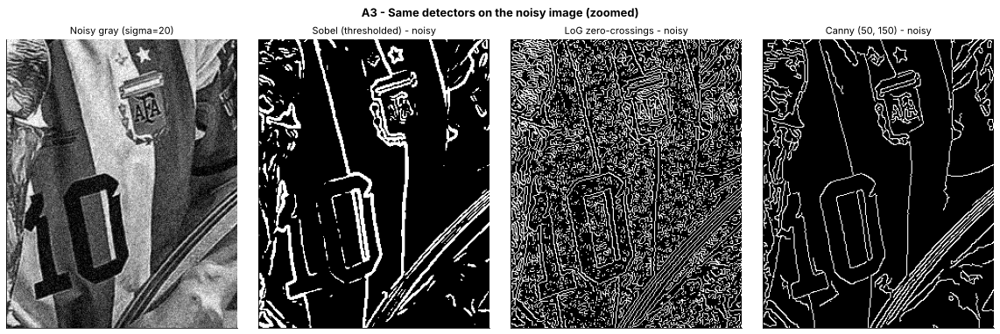

In [ ]:
# ---------------- A3: Sobel vs Laplacian vs Canny on the same smoothed image ----------------
gx = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=SOBEL_KSIZE)
gy = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=SOBEL_KSIZE)
sobel_mag = np.hypot(gx, gy)
sobel_dir = np.degrees(np.arctan2(gy, gx)) % 180
SOBEL_T = REF_PAIR[1]          # same magnitude scale as Canny's internal Sobel -> same "high" threshold
sobel_bin = (sobel_mag >= SOBEL_T).astype(np.uint8) * 255

lap = cv2.Laplacian(blur, cv2.CV_64F, ksize=LAPLACE_KSIZE)                 # discrete Laplacian of smoothed image
log = ndimage.gaussian_laplace(gray.astype(np.float64), sigma=LOG_SIGMA)   # LoG via SciPy (same scale)
log_zc = zero_crossings(log, LOG_ZC_T)
log_zc_all = zero_crossings(log, 0.0)
canny_ref = canny_maps[REF_PAIR]

# direction image: hue = orientation, value = magnitude
hsv = np.zeros((H, W, 3), np.uint8)
hsv[..., 0] = (sobel_dir / 180 * 179).astype(np.uint8); hsv[..., 1] = 255
hsv[..., 2] = np.clip(sobel_mag / np.percentile(sobel_mag, 99) * 255, 0, 255).astype(np.uint8)
dir_rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

fig, axes = plt.subplots(2, 3, figsize=(15, 15))
vmax = np.percentile(sobel_mag, 99)
axes[0, 0].imshow(sobel_mag, cmap="gray", vmax=vmax); axes[0, 0].set_title("Sobel |grad| (continuous magnitude)")
axes[0, 1].imshow(dir_rgb); axes[0, 1].set_title("Sobel direction (hue) x magnitude (brightness)")
lv = np.percentile(np.abs(lap), 99)
im = axes[0, 2].imshow(lap, cmap="RdBu_r", vmin=-lv, vmax=lv); axes[0, 2].set_title("Laplacian (signed 2nd derivative)")
fig.colorbar(im, ax=axes[0, 2], fraction=0.046, pad=0.02, label="d2I (grey levels / px^2)")
axes[1, 0].imshow(sobel_bin, cmap="gray"); axes[1, 0].set_title(f"Sobel |grad| >= {SOBEL_T} (binary)")
axes[1, 1].imshow(log_zc, cmap="gray"); axes[1, 1].set_title(f"LoG zero-crossings, sigma={LOG_SIGMA}, slope>{LOG_ZC_T}")
axes[1, 2].imshow(canny_ref, cmap="gray"); axes[1, 2].set_title(f"Canny {REF_PAIR}")
for a_ in axes.ravel(): a_.set_xticks([]); a_.set_yticks([])
fig.suptitle("A3 - Gradient (Sobel), second-derivative (Laplacian/LoG) and Canny responses"); plt.show()

show_grid([gray, sobel_bin, log_zc, log_zc_all, canny_ref],
          ["Grayscale", f"Sobel >= {SOBEL_T}", f"LoG zero-crossings (slope>{LOG_ZC_T})", "LoG zero-crossings (no slope test)", f"Canny {REF_PAIR}"],
          "A3 - Zoomed comparison: edge thickness and continuity", 5, (19, 5), crop=ZOOM)

comp = {"Sobel (thresholded)": sobel_bin, "LoG zero-crossings": log_zc, f"Canny {REF_PAIR}": canny_ref}
comp_m = {k: edge_metrics(v) for k, v in comp.items()}
EVID["a3_clean"] = comp_m
print_table(["method", "edge px", "density", "components", "mean comp. size (px)", "fragments <10px", "thickness (px/skeleton px)"],
            [[k, m["pixels"], m["density"], m["components"], m["mean_len"], f'{m["short_frac"]:.1%}', m["thickness"]] for k, m in comp_m.items()],
            title="Continuity and thickness on the clean image")

# Noise sensitivity (1): how much does each operator amplify pure noise, relative to a real edge?
rng = np.random.default_rng(SEED)
step = np.zeros((64, 64)); step[:, 32:] = 100.0                      # ideal 100-grey-level step edge
pure = rng.normal(0, NOISE_SIGMA, (512, 512))                        # zero-mean noise only
ops = {"Sobel |grad| (ksize 3)": lambda im: np.hypot(cv2.Sobel(im, cv2.CV_64F, 1, 0, ksize=SOBEL_KSIZE),
                                                     cv2.Sobel(im, cv2.CV_64F, 0, 1, ksize=SOBEL_KSIZE)),
       "Laplacian (ksize 3)": lambda im: cv2.Laplacian(im, cv2.CV_64F, ksize=LAPLACE_KSIZE)}
rows = []
for name, op in ops.items():
    for smooth in (False, True):
        f = (lambda im: cv2.GaussianBlur(im, GAUSS_KSIZE, GAUSS_SIGMA)) if smooth else (lambda im: im)
        sig = np.abs(op(f(step)))[:, 16:48].max()
        nstd = op(f(pure))[8:-8, 8:-8].std()
        rows.append([name, "yes" if smooth else "no", sig, nstd, sig / nstd])
EVID["a3_snr"] = rows
print_table(["operator", "Gaussian first", "peak response to 100-level step", "std of response to noise", "edge SNR"], rows,
            title=f"Noise amplification (noise sigma = {NOISE_SIGMA}); Canny uses the Sobel gradient internally")

# Noise sensitivity (2): add noise to the real image, rerun the identical pipeline
gray_noisy = np.clip(gray.astype(np.float64) + rng.normal(0, NOISE_SIGMA, gray.shape), 0, 255).astype(np.uint8)
blur_noisy = cv2.GaussianBlur(gray_noisy, GAUSS_KSIZE, GAUSS_SIGMA)
gxn = cv2.Sobel(blur_noisy, cv2.CV_64F, 1, 0, ksize=SOBEL_KSIZE); gyn = cv2.Sobel(blur_noisy, cv2.CV_64F, 0, 1, ksize=SOBEL_KSIZE)
noisy = {"Sobel (thresholded)": (np.hypot(gxn, gyn) >= SOBEL_T).astype(np.uint8) * 255,
         "LoG zero-crossings": zero_crossings(ndimage.gaussian_laplace(gray_noisy.astype(np.float64), LOG_SIGMA), LOG_ZC_T),
         f"Canny {REF_PAIR}": canny(blur_noisy, *REF_PAIR)}
k7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
rows, EVID["a3_noise"] = [], {}
for k in comp:
    mc, mn = comp_m[k], edge_metrics(noisy[k])
    free = cv2.dilate((comp[k] > 0).astype(np.uint8), k7) == 0          # >3 px away from any clean edge
    spurious = ((noisy[k] > 0) & free).sum() / free.sum()
    EVID["a3_noise"][k] = dict(dens_clean=mc["density"], dens_noisy=mn["density"],
                               increase=mn["density"] / mc["density"] - 1, frag_noisy=mn["short_frac"], spurious=spurious)
    rows.append([k, mc["density"], mn["density"], f'{mn["density"]/mc["density"]-1:+.1%}', f"{spurious:.2%}",
                 f'{mc["short_frac"]:.1%} -> {mn["short_frac"]:.1%}'])
print_table(["method", "density clean", "density noisy", "change", "false edges in edge-free areas", "fragments <10px"],
            rows, title=f"Real image + Gaussian noise (sigma={NOISE_SIGMA}), identical parameters")
show_grid([gray_noisy] + list(noisy.values()), [f"Noisy gray (sigma={NOISE_SIGMA})"] + [f"{k} - noisy" for k in noisy],
          "A3 - Same detectors on the noisy image (zoomed)", 4, (16, 5.2), crop=ZOOM)

**A3 discussion.**

| Criterion | Sobel (thresholded) | Laplacian / LoG zero-crossings | Canny (50, 150) |
|---|---|---|---|
| **Edge continuity** | 1,838 pieces, mean 65 px, **48.5 %** fragments; gaps wherever magnitude dips below $T$ | 8,987 pieces, mean 16 px, **78.4 %** fragments — zero-crossings also occur along every texture ripple | **1,001 pieces, mean 86 px, 6.6 % fragments** — hysteresis bridges weak sections |
| **Edge thickness** | **2.63 px** per skeleton px — a band as wide as the blurred ramp | 1.03 px (sign changes occur between pixels) | **1.05 px** (NMS) |
| **Noise sensitivity** | step SNR **20.0**; false edges 0.12 % — robust here only because one high threshold also discards weak *real* edges | step SNR only **3.9** (second derivative amplifies noise ≈5× more); false edges **18.6 %**, density +68.8 % | uses Sobel's SNR of 20; false edges 0.95 %, density +3.8 % — slightly more than thresholded Sobel because the low threshold (50) lets some noise connect to real edges |
| **Information produced** | continuous magnitude **and** direction per pixel (feeds HOG/SIFT) | signed scalar: location and *polarity* (which side is brighter), **no direction**, no single-threshold edge strength | binary map: *where* edges are, 1 px wide; magnitude and direction discarded |

**Interpretation.** Sobel measures *how strong* and *which way*; turned into a binary map with one threshold, it gives thick bands with gaps. The Laplacian localises well, but because it is a second derivative it is the most noise-sensitive, and it marks texture as heavily as object boundaries (see the "no slope test" panel). Canny is built from the Sobel gradient, then fixes its two weaknesses: NMS makes edges thin, and hysteresis makes them continuous. The cost is a small number of noise pixels attached through the low threshold.

## A4. A quantitative measure: edge-pixel density (1)

$$D=\frac{\#\{(x,y):E(x,y)=1\}}{H\times W}$$

Measured for the four pairs. Each parameter is then varied **on its own**: a full (low, high) grid; low only (high = 150); high only (low = 50); and Gaussian σ only (thresholds fixed at 50/150). A tile-wise density map shows *where* the edge pixels come from.

Edge-pixel density  D = (# edge pixels) / (H x W)
(low, high) | edge px | density | components | mean comp. size (px) | fragments <10px
-------------+---------+---------+------------+----------------------+-----------------
   (20, 60) | 147,500 |  0.1532 |      3,103 |                47.53 |           31.7%
  (50, 150) |  85,971 |  0.0893 |      1,001 |                85.89 |            6.6%
 (100, 200) |  58,119 |  0.0604 |        745 |                78.01 |            1.7%
 (150, 300) |  31,295 |  0.0325 |        346 |                90.45 |            0.0%



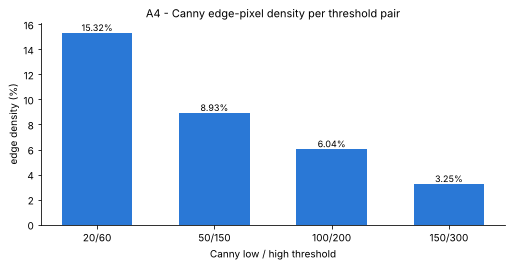

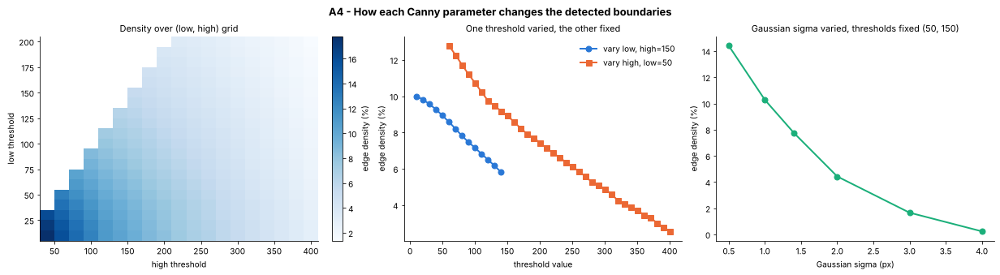

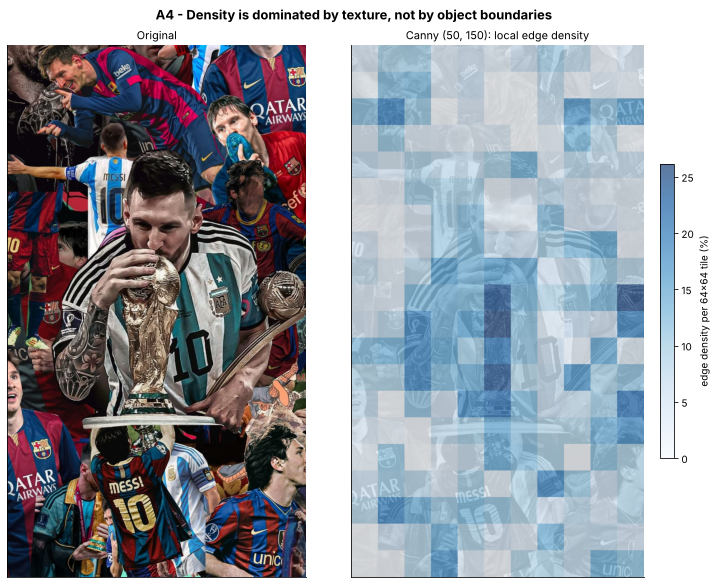

Tile densities: min=0.0%, median=8.4%, max=26.1%
Noisy image, Canny(50, 150): density 0.0927 vs clean 0.0893 -> higher density, but the extra pixels are noise.


In [ ]:
# ---------------- A4: edge-pixel density and parameter effects ----------------
dens = {p: edge_metrics(canny_maps[p]) for p in CANNY_PAIRS}
EVID["a4_pairs"] = {p: dens[p]["density"] for p in CANNY_PAIRS}
print_table(["(low, high)", "edge px", "density", "components", "mean comp. size (px)", "fragments <10px"],
            [[str(p), m["pixels"], m["density"], m["components"], m["mean_len"], f'{m["short_frac"]:.1%}'] for p, m in dens.items()],
            title="Edge-pixel density  D = (# edge pixels) / (H x W)")

fig, ax = plt.subplots(figsize=(7, 3.6))
labels = [f"{p[0]}/{p[1]}" for p in CANNY_PAIRS]
vals = [100 * dens[p]["density"] for p in CANNY_PAIRS]
ax.bar(labels, vals, color=C[0], width=0.6)
for i, v in enumerate(vals): ax.text(i, v + 0.15, f"{v:.2f}%", ha="center", fontsize=9)
ax.set(title="A4 - Canny edge-pixel density per threshold pair", xlabel="Canny low / high threshold", ylabel="edge density (%)")
plt.show()

# Controlled sweeps: (1) low x high grid, (2) low only, (3) high only, (4) Gaussian sigma only
lows  = np.arange(10, 210, 10); highs = np.arange(40, 420, 20)
grid = np.full((len(lows), len(highs)), np.nan)
for i, lo in enumerate(lows):
    for j, hi in enumerate(highs):
        if lo < hi: grid[i, j] = 100 * (canny(blur, int(lo), int(hi)) > 0).mean()
fixed_hi = REF_PAIR[1]; fixed_lo = REF_PAIR[0]
d_low  = [100 * (canny(blur, int(l), fixed_hi) > 0).mean() for l in range(10, fixed_hi, 10)]
d_high = [100 * (canny(blur, fixed_lo, int(h)) > 0).mean() for h in range(fixed_lo + 10, 410, 10)]
sigmas = [0.5, 1.0, 1.4, 2.0, 3.0, 4.0]
d_sig = [100 * (canny(cv2.GaussianBlur(gray, (0, 0), s), *REF_PAIR) > 0).mean() for s in sigmas]
EVID["a4_sigma"] = dict(zip(sigmas, d_sig))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
im = ax[0].imshow(grid, cmap="Blues", origin="lower", aspect="auto",
                  extent=[highs[0] - 10, highs[-1] + 10, lows[0] - 5, lows[-1] + 5])
fig.colorbar(im, ax=ax[0], label="edge density (%)")
ax[0].set(title="Density over (low, high) grid", xlabel="high threshold", ylabel="low threshold")
ax[1].plot(range(10, fixed_hi, 10), d_low, "o-", color=C[0], label=f"vary low, high={fixed_hi}")
ax[1].plot(range(fixed_lo + 10, 410, 10), d_high, "s-", color=C[1], label=f"vary high, low={fixed_lo}")
ax[1].set(title="One threshold varied, the other fixed", xlabel="threshold value", ylabel="edge density (%)"); ax[1].legend()
ax[2].plot(sigmas, d_sig, "o-", color=C[2])
ax[2].set(title=f"Gaussian sigma varied, thresholds fixed {REF_PAIR}", xlabel="Gaussian sigma (px)", ylabel="edge density (%)")
fig.suptitle("A4 - How each Canny parameter changes the detected boundaries"); plt.show()

# Limitation evidence: where does the density come from? (tile-wise density map)
T = 64
tiles = (canny_maps[REF_PAIR][:H // T * T, :W // T * T] > 0).reshape(H // T, T, W // T, T).mean(axis=(1, 3)) * 100
fig, ax = plt.subplots(1, 2, figsize=(10, 8))
ax[0].imshow(rgb); ax[0].set_title("Original")
ax[1].imshow(gray, cmap="gray", alpha=0.5)
im = ax[1].imshow(np.kron(tiles, np.ones((T, T))), cmap="Blues", alpha=0.65, extent=[0, W // T * T, H // T * T, 0])
fig.colorbar(im, ax=ax[1], fraction=0.046, label=f"edge density per {T}x{T} tile (%)")
ax[1].set_title(f"Canny {REF_PAIR}: local edge density")
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
fig.suptitle("A4 - Density is dominated by texture, not by object boundaries"); plt.show()
EVID["a4_tiles"] = dict(max=float(tiles.max()), min=float(tiles.min()), median=float(np.median(tiles)))
print(f"Tile densities: min={tiles.min():.1f}%, median={np.median(tiles):.1f}%, max={tiles.max():.1f}%")
print(f"Noisy image, Canny{REF_PAIR}: density {EVID['a3_noise'][f'Canny {REF_PAIR}']['dens_noisy']:.4f} "
      f"vs clean {EVID['a3_noise'][f'Canny {REF_PAIR}']['dens_clean']:.4f} -> higher density, but the extra pixels are noise.")

**How parameters affect the detected boundaries.**
* **Thresholds.** Density falls monotonically with both thresholds: 15.3 % → 8.9 % → 6.0 % → 3.3 % for the four pairs. In the one-at-a-time sweep, lowering *low* from 140 to 10 (high fixed at 150) adds about 4 points of density by extending existing contours. Changing *high* has the larger effect (from about 12.8 % to 2.6 % across its range) because it controls which contours are seeded at all.
* **Gaussian σ.** σ = 0.5 → 14.4 %, 1.0 → 10.3 %, 2.0 → 4.4 %, 3.0 → 1.7 %, 4.0 → 0.2 %. Smoothing reduces gradient magnitude ($\approx h/(\sigma\sqrt{2\pi})$ for a step of height $h$), so the same thresholds pass fewer pixels and fine boundaries disappear first. *(In this sweep the kernel size is derived from σ, ≈6σ+1. That is why σ = 1.4 gives 7.8 % here but 8.9 % with the fixed 5×5 kernel, which truncates the Gaussian's tails and smooths slightly less.)*

**Limitation of the measure.** Density counts pixels; it does not judge *correctness*. The tile map shows the densest tiles (up to 26 %) on the **trophy's relief and the ball on the right** — texture, not object boundaries — while large uniform areas such as the jersey have almost none. Adding noise raised Canny's density by 3.8 % without adding a single real boundary, and the LoG's by 68.8 %. A higher $D$ can therefore mean *more noise*, not *better detection*. $D$ also ignores continuity and position, and it depends on image resolution. A sound evaluation needs ground-truth boundaries (precision/recall/F-measure, as in the BSDS benchmark).

---
# Part B — Histogram of Oriented Gradients (HOG)

## B1. HOG features of a clearly defined region (2)

**Region.** The central subject — face, hands, trophy and jersey — at $x\in[112,623]$, $y\in[256,895]$: **512 × 640 px**. Both sides are multiples of 8 and 16, so cells and blocks tile it exactly. The ROI is used **unsmoothed**: Dalal & Triggs found that any Gaussian pre-smoothing degrades HOG, because it blurs the gradients HOG relies on.

**Parameters (Dalal–Triggs defaults):** centred $[-1,0,1]$ gradient, 8×8-px cells, 9 unsigned bins (20° each), 2×2-cell blocks with stride 1 cell, L2-Hys normalisation (clip 0.2).

HOG is implemented from scratch in NumPy so every stage can be inspected, and its dimension is cross-checked against `cv2.HOGDescriptor`.

**Dimension.**
$$n_{cx}=\tfrac{512}{8}=64,\quad n_{cy}=\tfrac{640}{8}=80,\qquad n_{bx}=64-2+1=63,\quad n_{by}=80-2+1=79$$
$$D = n_{bx}\,n_{by}\times(2\times2\times9)=4{,}977\times36=\mathbf{179{,}172}$$

**Visualisation.** Each cell shows one line per orientation bin, drawn **perpendicular to the gradient** (that is, along the edge), with brightness proportional to the bin's vote (square-root display scale).

HOG region          : x=112..623, y=256..895  ->  512 x 640 px (uint8 gray, no smoothing)
Cell / block / bins : 8x8 px  /  2x2 cells, stride 1 cell  /  9 bins over 0-180 deg
Cells               : 64 x 80 = 5,120
Blocks              : (64-2+1) x (80-2+1) = 63 x 79 = 4,977
Values per block    : 2*2*9 = 36
FEATURE VECTOR      : 4,977 x 36 = 179,172 dimensions  (our implementation: (179172,))
OpenCV HOGDescriptor: 179,172 dimensions  ->  MATCH
Value range         : [0.000, 0.707] (clipped at 0.2 before renormalising)


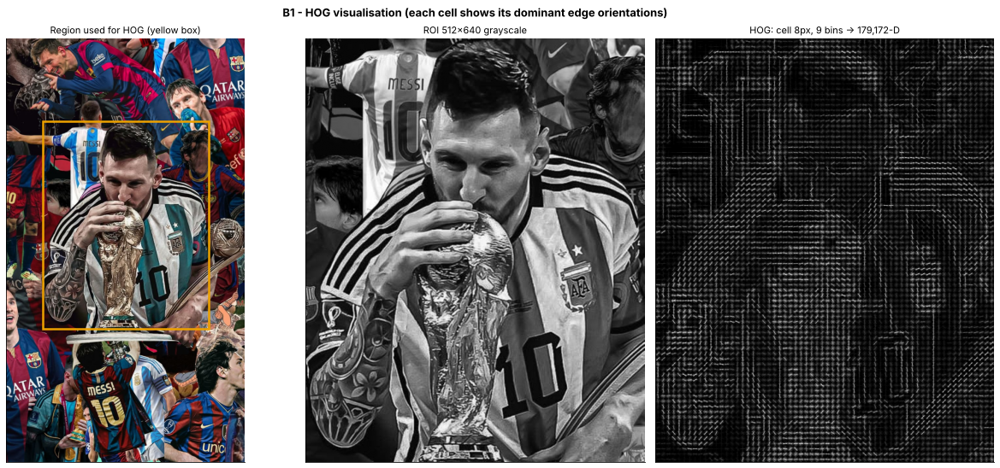

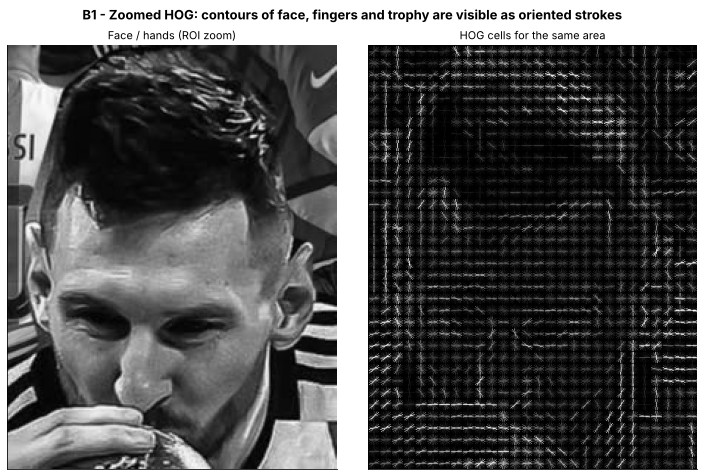

In [ ]:
# ---------------- B1: HOG implemented from first principles ----------------
def hog_gradients(img):
    """Centred differences [-1, 0, 1] (Dalal & Triggs best performer), unsigned orientation in [0, 180)."""
    f = img.astype(np.float32)
    gx = cv2.filter2D(f, cv2.CV_32F, np.array([[-1, 0, 1]], np.float32))
    gy = cv2.filter2D(f, cv2.CV_32F, np.array([[-1], [0], [1]], np.float32))
    return np.hypot(gx, gy), np.degrees(np.arctan2(gy, gx)) % 180.0

def hog_cell_histograms(mag, ang, cell, nbins):
    """Magnitude-weighted orientation histogram per cell, with linear vote-splitting between the two nearest bins."""
    ncy, ncx = mag.shape[0] // cell, mag.shape[1] // cell
    mag, ang = mag[:ncy * cell, :ncx * cell], ang[:ncy * cell, :ncx * cell]
    bw = 180.0 / nbins
    pos = ang / bw - 0.5                       # bin centres at (k + 0.5) * bw
    b0 = np.floor(pos).astype(np.int64)
    w1 = pos - b0; w0 = 1.0 - w1
    cy = (np.arange(ncy * cell) // cell)[:, None]; cx = (np.arange(ncx * cell) // cell)[None, :]
    cidx = (cy * ncx + cx) * nbins
    n = ncy * ncx * nbins
    hist = (np.bincount((cidx + b0 % nbins).ravel(), (mag * w0).ravel(), n) +
            np.bincount((cidx + (b0 + 1) % nbins).ravel(), (mag * w1).ravel(), n))
    return hist.reshape(ncy, ncx, nbins)

def hog_blocks(hist, block, clip=HOG_CLIP, eps=1e-6):
    """Overlapping blocks (stride = 1 cell), L2-Hys normalisation: L2 -> clip at `clip` -> L2 again."""
    win = np.lib.stride_tricks.sliding_window_view(hist, (block, block), axis=(0, 1))  # (nby, nbx, bins, b, b)
    v = win.transpose(0, 1, 3, 4, 2).reshape(win.shape[0], win.shape[1], -1).astype(np.float64)
    v = v / np.sqrt((v ** 2).sum(-1, keepdims=True) + eps ** 2)
    v = np.minimum(v, clip)
    v = v / np.sqrt((v ** 2).sum(-1, keepdims=True) + eps ** 2)
    return v

def hog(img, cell=HOG_CELL, block=HOG_BLOCK, nbins=HOG_BINS):
    t0 = time.perf_counter()
    mag, ang = hog_gradients(img)
    hist = hog_cell_histograms(mag, ang, cell, nbins)
    blocks = hog_blocks(hist, block)
    feat = blocks.ravel()
    return dict(feat=feat, hist=hist, blocks=blocks, mag=mag, ang=ang, ms=1000 * (time.perf_counter() - t0))

def hog_visualise(hist, cell, nbins, min_px=16):
    """Draw, in every cell, one line per bin along the EDGE direction (gradient + 90 deg); brightness = bin value."""
    s = max(1, min_px // cell); c = cell * s
    ncy, ncx, _ = hist.shape
    canvas = np.zeros((ncy * c, ncx * c), np.float32)
    norm = np.sqrt(hist / (np.percentile(hist, 99) + 1e-9))   # square-root display scale so weak cells stay visible
    centres = (np.arange(nbins) + 0.5) * 180.0 / nbins
    dx = np.cos(np.radians(centres + 90)) * c * 0.45
    dy = np.sin(np.radians(centres + 90)) * c * 0.45
    for i in range(ncy):
        for j in range(ncx):
            yc, xc = i * c + c / 2, j * c + c / 2
            for b in np.argsort(norm[i, j]):            # strongest bin drawn last (on top)
                v = float(min(norm[i, j, b], 1.0))
                if v < 0.02: continue
                cv2.line(canvas, (int(round(xc - dx[b])), int(round(yc - dy[b]))),
                         (int(round(xc + dx[b])), int(round(yc + dy[b]))), v, 1, cv2.LINE_AA)
    return canvas, s

def hog_dims(h, w, cell, block, nbins):
    ncy, ncx = h // cell, w // cell
    nby, nbx = ncy - block + 1, ncx - block + 1
    return ncy, ncx, nby, nbx, nby * nbx * block * block * nbins

rx, ry, rw, rh = HOG_ROI
roi = gray[ry:ry + rh, rx:rx + rw]          # unsmoothed: Dalal & Triggs found sigma=0 works best for HOG
H8 = hog(roi)
ncy, ncx, nby, nbx, D = hog_dims(rh, rw, HOG_CELL, HOG_BLOCK, HOG_BINS)
assert H8["feat"].size == D

# Cross-check the dimension with OpenCV's built-in HOGDescriptor (same window/cell/block/bins)
cv_hog = cv2.HOGDescriptor((rw, rh), (HOG_BLOCK * HOG_CELL,) * 2, (HOG_CELL, HOG_CELL), (HOG_CELL, HOG_CELL), HOG_BINS)
cv_feat = cv_hog.compute(roi)
EVID["b1"] = dict(D=D, ncy=ncy, ncx=ncx, nby=nby, nbx=nbx, ms=H8["ms"])

print(f"HOG region          : x={rx}..{rx+rw-1}, y={ry}..{ry+rh-1}  ->  {rw} x {rh} px (uint8 gray, no smoothing)")
print(f"Cell / block / bins : {HOG_CELL}x{HOG_CELL} px  /  {HOG_BLOCK}x{HOG_BLOCK} cells, stride 1 cell  /  {HOG_BINS} bins over 0-180 deg")
print(f"Cells               : {ncx} x {ncy} = {ncx*ncy:,}")
print(f"Blocks              : ({ncx}-{HOG_BLOCK}+1) x ({ncy}-{HOG_BLOCK}+1) = {nbx} x {nby} = {nbx*nby:,}")
print(f"Values per block    : {HOG_BLOCK}*{HOG_BLOCK}*{HOG_BINS} = {HOG_BLOCK*HOG_BLOCK*HOG_BINS}")
print(f"FEATURE VECTOR      : {nbx*nby:,} x {HOG_BLOCK*HOG_BLOCK*HOG_BINS} = {D:,} dimensions  (our implementation: {H8['feat'].shape})")
print(f"OpenCV HOGDescriptor: {cv_feat.size:,} dimensions  ->  {'MATCH' if cv_feat.size == D else 'MISMATCH'}")
print(f"Value range         : [{H8['feat'].min():.3f}, {H8['feat'].max():.3f}] (clipped at {HOG_CLIP} before renormalising)")

viz8, s8 = hog_visualise(H8["hist"], HOG_CELL, HOG_BINS)
fig, ax = plt.subplots(1, 3, figsize=(17, 7.5))
ax[0].imshow(rgb); ax[0].add_patch(Rectangle((rx, ry), rw, rh, fill=False, ec=C[3], lw=2.5))
ax[0].set_title("Region used for HOG (yellow box)")
ax[1].imshow(roi, cmap="gray"); ax[1].set_title(f"ROI {rw}x{rh} grayscale")
ax[2].imshow(viz8, cmap="gray"); ax[2].set_title(f"HOG: cell {HOG_CELL}px, {HOG_BINS} bins -> {D:,}-D")
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
fig.suptitle("B1 - HOG visualisation (each cell shows its dominant edge orientations)"); plt.show()

FZ = (160, 0, 224, 288)    # face region inside the ROI (x, y, w, h), multiples of 16
fx, fy, fw, fh = FZ
fig, ax = plt.subplots(1, 2, figsize=(10, 6.5))
ax[0].imshow(roi[fy:fy + fh, fx:fx + fw], cmap="gray"); ax[0].set_title("Face / hands (ROI zoom)")
ax[1].imshow(viz8[fy * s8:(fy + fh) * s8, fx * s8:(fx + fw) * s8], cmap="gray"); ax[1].set_title("HOG cells for the same area")
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
fig.suptitle("B1 - Zoomed HOG: contours of face, fingers and trophy are visible as oriented strokes"); plt.show()

**B1 result.** The feature vector has **179,172 dimensions** (4,977 blocks × 36), identical to OpenCV's `HOGDescriptor` for the same settings. In the visualisation, the strokes follow the head outline, the hairline, the fingers wrapped around the trophy, the diagonal sleeve stripes and the vertical jersey stripes. Uniform regions (skin, the plain white jersey) give short, faint strokes. HOG keeps the *layout of edge directions* and discards the intensities themselves.

## B2. What each stage contributes to the descriptor (2)

1. **Image gradients.** $g_x=I(x{+}1,y)-I(x{-}1,y)$, $g_y=I(x,y{+}1)-I(x,y{-}1)$, magnitude $m=\sqrt{g_x^2+g_y^2}$, orientation $\theta=\operatorname{atan2}(g_y,g_x)\bmod 180^\circ$. Gradients make the descriptor depend on **shape (intensity changes)** rather than absolute brightness. *Unsigned* orientation treats a dark-on-light edge the same as light-on-dark, which helps when clothing or background colours swap.
2. **Orientation histograms.** Each pixel adds its magnitude $m$ to the histogram, split linearly between the two nearest bin centres $c_k=(k+\tfrac12)\cdot20^\circ$: weight $1-\frac{|\theta-c_k|}{20^\circ}$ to the nearer bin, the rest to the other. Strong edges dominate the vote, and splitting avoids a jump when θ crosses a bin boundary.
3. **Cells (8×8 px).** Pooling over a cell turns 64 pixels × 2 values into 9 numbers and makes the descriptor tolerant to shifts of a few pixels *within* the cell, while keeping coarse *spatial* layout across cells.
4. **Blocks (2×2 cells, overlapping).** Each block concatenates 4 cell histograms (36 values). Because blocks overlap with a stride of one cell, each interior cell appears in 4 blocks, each time normalised against a different neighbourhood. This redundancy improved detection in Dalal–Triggs' experiments.
5. **Normalisation (L2-Hys).** $v\leftarrow v/\sqrt{\lVert v\rVert_2^2+\varepsilon^2}$, then $v_i\leftarrow\min(v_i,0.2)$, then re-normalise. The first step cancels local **contrast/illumination**. Clipping stops one very strong edge (the dashed line at 0.2 in panel 4) from dominating the block, so weaker but informative orientations still count.

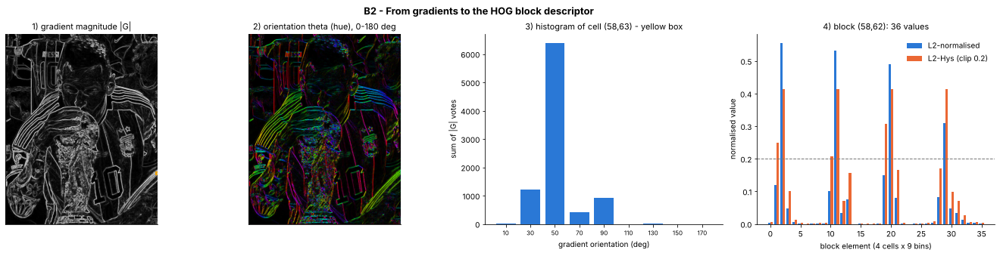

Gradient magnitudes scale with contrast, but the normalised HOG vector does not
illumination change       | raw cell-hist scale | cos(raw hists) | max |diff| final HOG | cos(final HOG)
---------------------------+---------------------+----------------+----------------------+----------------
            contrast x0.5 |              0.5000 |         1.0000 |               0.0000 |         1.0000
contrast x0.6 + 60 offset |              0.6000 |         1.0000 |               0.0000 |         1.0000
   gamma 0.5 (non-linear) |              0.9061 |         0.9814 |               0.2958 |         0.9924



In [ ]:
# ---------------- B2: what each HOG stage contributes ----------------
hist = H8["hist"]
ci, cj = np.unravel_index(np.argmax(hist.sum(-1)), hist.shape[:2])    # most textured cell
bi, bj = min(ci, nby - 1), min(cj, nbx - 1)
raw_block = hist[bi:bi + HOG_BLOCK, bj:bj + HOG_BLOCK].reshape(-1)
l2 = raw_block / np.linalg.norm(raw_block)
centres = (np.arange(HOG_BINS) + 0.5) * 180 / HOG_BINS

fig, ax = plt.subplots(1, 4, figsize=(19, 4.6))
ax[0].imshow(H8["mag"], cmap="gray", vmax=np.percentile(H8["mag"], 99)); ax[0].set_title("1) gradient magnitude |G|")
ax[0].add_patch(Rectangle((cj * HOG_CELL, ci * HOG_CELL), HOG_CELL, HOG_CELL, fill=False, ec=C[3], lw=2))
hsv_r = np.zeros((rh, rw, 3), np.uint8); hsv_r[..., 0] = (H8["ang"] / 180 * 179).astype(np.uint8); hsv_r[..., 1] = 255
hsv_r[..., 2] = np.clip(H8["mag"] / np.percentile(H8["mag"], 99) * 255, 0, 255).astype(np.uint8)
ax[1].imshow(cv2.cvtColor(hsv_r, cv2.COLOR_HSV2RGB)); ax[1].set_title("2) orientation theta (hue), 0-180 deg")
for a_ in ax[:2]: a_.set_xticks([]); a_.set_yticks([])
ax[2].bar(centres, hist[ci, cj], width=180 / HOG_BINS * 0.8, color=C[0])
ax[2].set(title=f"3) histogram of cell ({ci},{cj}) - yellow box", xlabel="gradient orientation (deg)", ylabel="sum of |G| votes", xticks=centres)
ax[2].tick_params(axis="x", labelsize=8)
xb = np.arange(raw_block.size)
ax[3].bar(xb - 0.2, l2, width=0.4, color=C[0], label="L2-normalised")
ax[3].bar(xb + 0.2, H8["blocks"][bi, bj], width=0.4, color=C[1], label=f"L2-Hys (clip {HOG_CLIP})")
ax[3].axhline(HOG_CLIP, color="#777", lw=1, ls="--")
ax[3].set(title=f"4) block ({bi},{bj}): {raw_block.size} values", xlabel="block element (4 cells x 9 bins)", ylabel="normalised value"); ax[3].legend()
fig.suptitle("B2 - From gradients to the HOG block descriptor"); plt.show()

# Why block normalisation matters: change illumination/contrast and compare descriptors
def cos(a, b): return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))
dark   = (roi.astype(np.float32) * 0.5).astype(np.float32)                     # contrast halved
bright = np.clip(roi.astype(np.float32) * 0.6 + 60, 0, 255).astype(np.float32)  # contrast + brightness change
rows = []
gamma = (255.0 * (roi / 255.0) ** 0.5).astype(np.float32)                    # non-linear (gamma 0.5) change
for name, im_ in [("contrast x0.5", dark), ("contrast x0.6 + 60 offset", bright), ("gamma 0.5 (non-linear)", gamma)]:
    Hx = hog(im_)
    rows.append([name, float(np.mean(Hx["hist"]) / np.mean(hist)), cos(hist.ravel(), Hx["hist"].ravel()),
                 float(np.abs(Hx["feat"] - H8["feat"]).max()), cos(H8["feat"], Hx["feat"])])
EVID["b2_illum"] = rows
print_table(["illumination change", "raw cell-hist scale", "cos(raw hists)", "max |diff| final HOG", "cos(final HOG)"], rows,
            title="Gradient magnitudes scale with contrast, but the normalised HOG vector does not")

**Evidence for normalisation.** Halving the contrast scales the raw cell histograms by exactly 0.50, yet the final HOG vector is **unchanged** (max |difference| 0.0000, cosine similarity 1.0000). An offset of +60 grey levels does not change gradients at all. A *non-linear* gamma-0.5 change alters the relative gradient strengths, so the descriptor is only approximately invariant (cosine **0.992**). Block normalisation removes local linear illumination changes but cannot fully undo non-linear ones.

## B3. Changing HOG parameters: detail vs dimensionality (1)

Two controlled sweeps on the same ROI (block = 2×2 cells, L2-Hys throughout):
* **cell size** ∈ {4, 8, 16} px with 9 bins;
* **orientation bins** ∈ {4, 9, 18} with 8-px cells.

From B1, $D=(\tfrac{W}{c}-1)(\tfrac{H}{c}-1)\cdot b^2\cdot n$, so $D\propto 1/c^2$ and $D\propto n$.

Controlled HOG parameter sweep (block = 2x2 cells, L2-Hys, same ROI)
varied             | value | cells  | feature dims | relative to default | spatial / angular resolution | time (ms)
--------------------+-------+--------+--------------+---------------------+------------------------------+-----------
cell size (bins=9) |  4 px | 20,480 |      726,948 |               4.06x |                4 px / 20 deg |     24.89
cell size (bins=9) |  8 px |  5,120 |      179,172 |               1.00x |                8 px / 20 deg |     18.88
cell size (bins=9) | 16 px |  1,280 |       43,524 |               0.24x |               16 px / 20 deg |     18.01
     bins (cell=8) |     4 |  5,120 |       79,632 |               0.44x |                8 px / 45 deg |     19.50
     bins (cell=8) |     9 |  5,120 |      179,172 |               1.00x |                8 px / 20 deg |     19.27
     bins (cell=8) |    18 |  5,120 |      358,344 |               2.00x |                8 px / 10 deg |     19.18



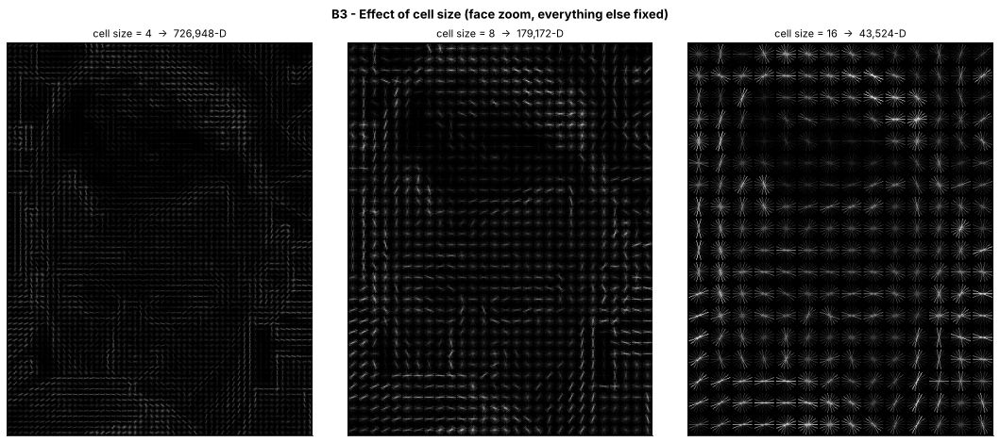

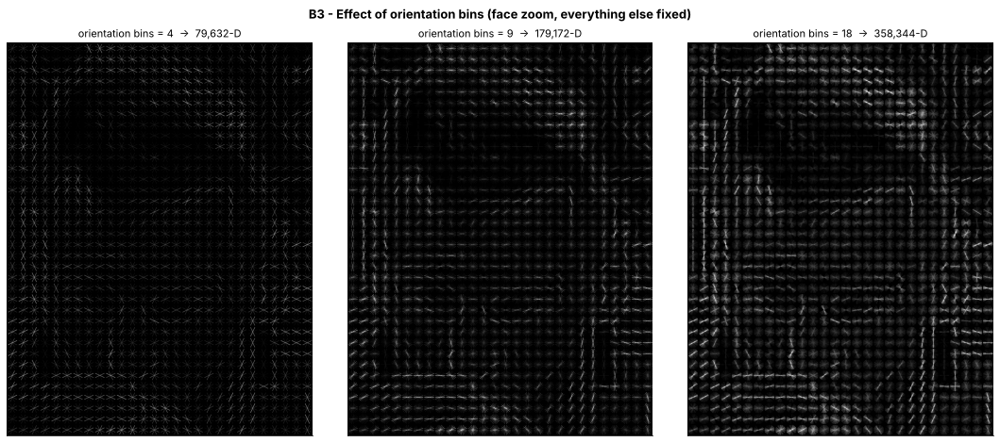

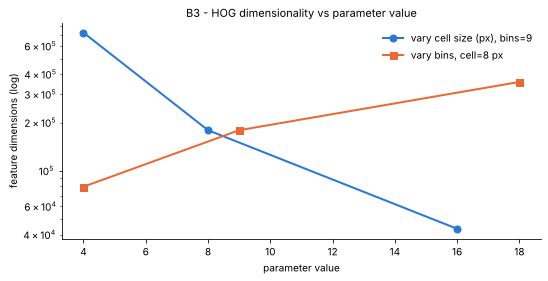

In [ ]:
# ---------------- B3: vary one HOG parameter at a time ----------------
def sweep(param, values):
    out = []
    for v in values:
        kw = dict(cell=HOG_CELL, block=HOG_BLOCK, nbins=HOG_BINS); kw[param] = v
        Hs = hog(roi, **kw)
        _, _, nby_, nbx_, D_ = hog_dims(rh, rw, kw["cell"], kw["block"], kw["nbins"])
        out.append(dict(val=v, D=D_, ms=Hs["ms"], hist=Hs["hist"], cells=Hs["hist"].shape[0] * Hs["hist"].shape[1],
                        res=f'{kw["cell"]} px / {180/kw["nbins"]:.0f} deg', kw=kw))
    return out

cell_sw = sweep("cell", [4, 8, 16])
bin_sw  = sweep("nbins", [4, 9, 18])
EVID["b3_cell"] = {r["val"]: r["D"] for r in cell_sw}
EVID["b3_bins"] = {r["val"]: r["D"] for r in bin_sw}
print_table(["varied", "value", "cells", "feature dims", "relative to default", "spatial / angular resolution", "time (ms)"],
            [["cell size (bins=9)", f'{r["val"]} px', r["cells"], r["D"], f'{r["D"]/D:.2f}x', r["res"], r["ms"]] for r in cell_sw] +
            [["bins (cell=8)", r["val"], r["cells"], r["D"], f'{r["D"]/D:.2f}x', r["res"], r["ms"]] for r in bin_sw],
            title="Controlled HOG parameter sweep (block = 2x2 cells, L2-Hys, same ROI)")

for sw, label in [(cell_sw, "cell size"), (bin_sw, "orientation bins")]:
    fig, ax = plt.subplots(1, 3, figsize=(15, 6.4))
    for a_, r in zip(ax, sw):
        v, s = hog_visualise(r["hist"], r["kw"]["cell"], r["kw"]["nbins"], min_px=32)
        a_.imshow(v[fy * s:(fy + fh) * s, fx * s:(fx + fw) * s], cmap="gray")
        a_.set_title(f'{label} = {r["val"]}  ->  {r["D"]:,}-D'); a_.set_xticks([]); a_.set_yticks([])
    fig.suptitle(f"B3 - Effect of {label} (face zoom, everything else fixed)"); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot([r["val"] for r in cell_sw], [r["D"] for r in cell_sw], "o-", color=C[0], label="vary cell size (px), bins=9")
ax.plot([r["val"] for r in bin_sw], [r["D"] for r in bin_sw], "s-", color=C[1], label="vary bins, cell=8 px")
ax.set_yscale("log"); ax.set(title="B3 - HOG dimensionality vs parameter value", xlabel="parameter value", ylabel="feature dimensions (log)")
ax.legend(); plt.show()

**Trade-off.**
* **Cell size.** 4-px cells give **726,948-D** (4.06×). The visualisation resolves individual hair strands and finger edges, but each histogram is built from only 16 pixels, making it noisy and sensitive to one-pixel misalignment, and a classifier trained on it needs far more data. 16-px cells give **43,524-D** (0.24×) and keep only the dominant contours. Many cells show "star" patterns: several unrelated orientations mixed together in one large cell, which is lost detail.
* **Bins.** 4 bins (45° each, **79,632-D**) cannot distinguish a 30° sleeve stripe from a 60° finger edge. 18 bins (10° each, **358,344-D**) doubles the size for finer angles that the data barely needs; Dalal–Triggs found no gain beyond about 9 bins.
* Dimension grows with the *square* of spatial resolution but only *linearly* with angular resolution. **8-px cells with 9 bins** is the balance point: it resolves the parts that define shape (face outline, hands, trophy) at a manageable size.

---
# Part C — SIFT Feature Detection and Description

## C1. Keypoints and descriptors (2)

**How SIFT works (Lowe, 2004).**
1. **Scale space:** $L(x,y,\sigma)=G_\sigma*I$ over octaves (each octave halves the resolution) with 3 intervals per octave. **Difference of Gaussians:** $D=L(x,y,k\sigma)-L(x,y,\sigma)\approx(k-1)\,\sigma^2\nabla^2G*I$, a cheap scale-normalised Laplacian of Gaussian.
2. **Extrema detection:** a sample is a candidate if it is larger or smaller than all 26 neighbours in its 3×3×3 (x, y, scale) neighbourhood. A quadratic Taylor fit then gives sub-pixel, sub-scale position.
3. **Rejection:** low contrast ($|D|$ below a threshold set by `contrastThreshold` = 0.04) is removed. Edge-like points, which are poorly localised along the edge, are removed with the Hessian test $\mathrm{Tr}(H)^2/\det(H)<(r+1)^2/r$, $r$ = `edgeThreshold` = 10.
4. **Orientation:** a 36-bin histogram of gradient directions around the point (Gaussian-weighted, $1.5\sigma$). The peak, and any peak above 80 % of it, becomes a keypoint orientation.
5. **Descriptor:** a 16×16 neighbourhood, **rotated to the keypoint orientation** and **scaled to its σ**, split into 4×4 sub-regions with an 8-bin orientation histogram each → $4\times4\times8=\mathbf{128}$ values, L2-normalised, clipped at 0.2 and renormalised (the same trick as HOG's L2-Hys).

**Parameters:** Lowe's defaults (3 layers per octave, contrast 0.04, edge ratio 10, base σ = 1.6) — the values his repeatability experiments found best. The raw grayscale image is used: SIFT does its own smoothing to σ = 1.6, and extra blur would wipe out the finest scale, where most keypoints are found (shown below).

SIFT parameters     : {'nfeatures': 0, 'nOctaveLayers': 3, 'contrastThreshold': 0.04, 'edgeThreshold': 10, 'sigma': 1.6}
Keypoints detected  : 9,469
Descriptor matrix   : (9469, 128)  dtype=float32  -> each descriptor = 4x4 spatial cells x 8 orientation bins = 128-D
Keypoint size (diam): min=1.8px, median=2.6px, max=131.1px
Keypoints per octave: {-1: 6569, 0: 1999, 1: 627, 2: 195, 3: 71, 4: 7, 5: 1} (-1 = up-sampled base image)
Detection+description time: 356 ms


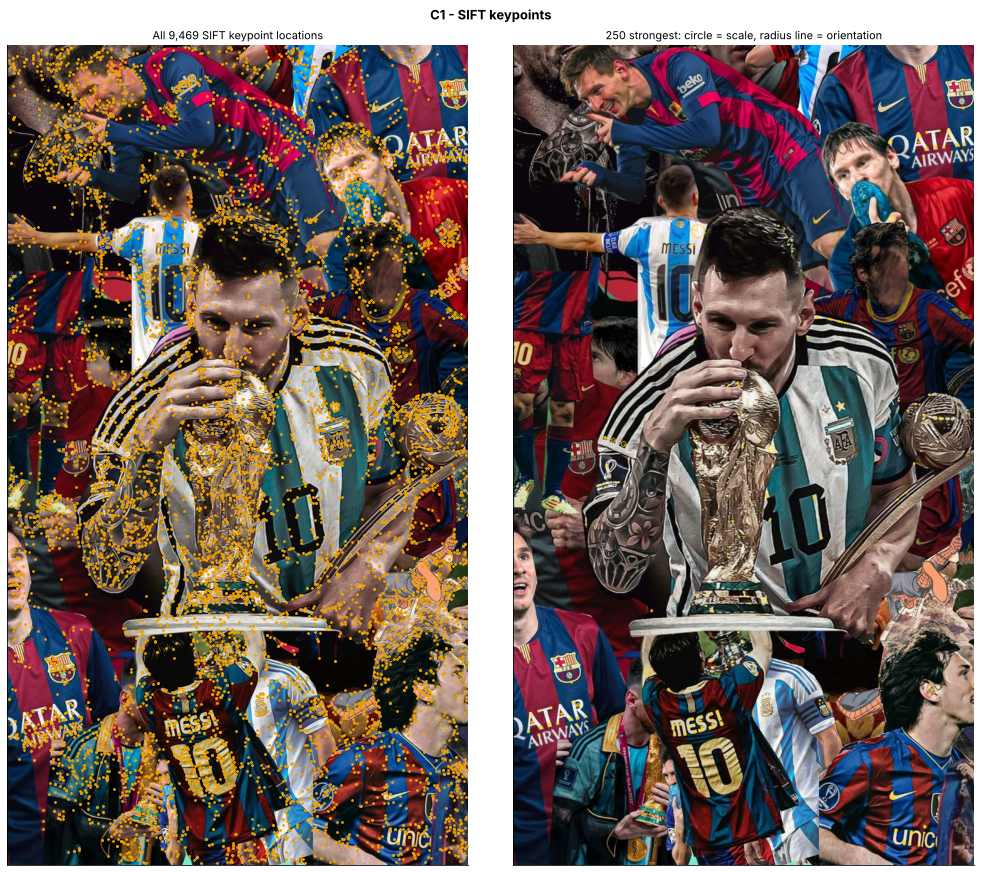

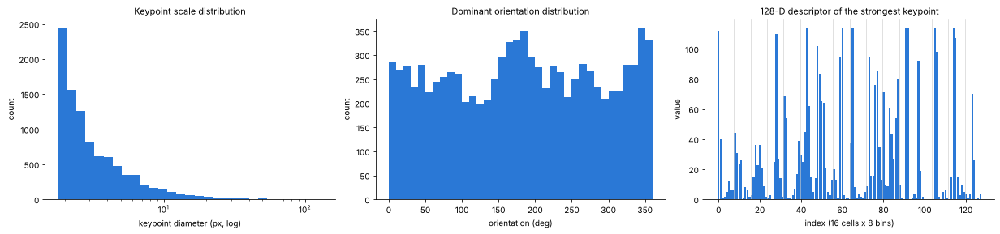

In [ ]:
# ---------------- C1: SIFT keypoints and descriptors ----------------
sift = cv2.SIFT_create(**SIFT_PARAMS)
t0 = time.perf_counter()
kp1, des1 = sift.detectAndCompute(gray, None)    # SIFT builds its own Gaussian scale space -> raw gray input
sift_ms = 1000 * (time.perf_counter() - t0)

def unpack_octave(kp):
    o = kp.octave & 255
    return o - 256 if o >= 128 else o

octs = np.array([unpack_octave(k) for k in kp1])
sizes = np.array([k.size for k in kp1]); oris = np.array([k.angle for k in kp1])
EVID["c1"] = dict(n=len(kp1), shape=des1.shape, ms=sift_ms)

print(f"SIFT parameters     : {SIFT_PARAMS}")
print(f"Keypoints detected  : {len(kp1):,}")
print(f"Descriptor matrix   : {des1.shape}  dtype={des1.dtype}  -> each descriptor = 4x4 spatial cells x 8 orientation bins = 128-D")
print(f"Keypoint size (diam): min={sizes.min():.1f}px, median={np.median(sizes):.1f}px, max={sizes.max():.1f}px")
print("Keypoints per octave:", {int(o): int((octs == o).sum()) for o in np.unique(octs)}, "(-1 = up-sampled base image)")
print(f"Detection+description time: {sift_ms:.0f} ms")

top = sorted(kp1, key=lambda k: -k.response)[:250]
rich = cv2.drawKeypoints(rgb, top, None, color=(255, 210, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
fig, ax = plt.subplots(1, 2, figsize=(14, 12))
ax[0].imshow(rgb); ax[0].scatter([k.pt[0] for k in kp1], [k.pt[1] for k in kp1], s=3, c=C[3])
ax[0].set_title(f"All {len(kp1):,} SIFT keypoint locations")
ax[1].imshow(rich); ax[1].set_title("250 strongest: circle = scale, radius line = orientation")
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
fig.suptitle("C1 - SIFT keypoints"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 3.9))
ax[0].hist(sizes, bins=np.logspace(np.log10(sizes.min()), np.log10(sizes.max()), 30), color=C[0])
ax[0].set_xscale("log"); ax[0].set(title="Keypoint scale distribution", xlabel="keypoint diameter (px, log)", ylabel="count")
ax[1].hist(oris, bins=36, range=(0, 360), color=C[0])
ax[1].set(title="Dominant orientation distribution", xlabel="orientation (deg)", ylabel="count")
k0 = int(np.argmax([k.response for k in kp1]))
ax[2].bar(np.arange(128), des1[k0], color=C[0], width=0.9)
for x in range(8, 128, 8): ax[2].axvline(x - 0.5, color="#ccc", lw=0.6)
ax[2].set(title=f"128-D descriptor of the strongest keypoint", xlabel="index (16 cells x 8 bins)", ylabel="value")
plt.show()

**C1 result.** **9,469 keypoints**; descriptor matrix **9,469 × 128**, `float32`. Keypoint diameters range from 1.8 px to 131 px (median 2.6 px). **69 %** (6,569) come from the up-sampled base octave — fine texture such as the trophy relief, letters and fabric — and the count falls roughly by a factor of 3 with each octave (1,999 / 627 / 195 / 71 / 7 / 1). In the rich-keypoint view, large circles sit on large structures (the face, the ball, the trophy body) and small circles on fine detail. Orientations cover all 360°, with peaks near 0°/180°/360° from the many horizontal and vertical structures (collage seams, lettering).

## C2. Matching against a rotated and scaled copy (2)

**Transformation.** Rotate **30° counter-clockwise** and scale by **0.75** about the image centre, on an enlarged canvas so nothing is cropped. Because the 2×3 matrix $M$ is known exactly, every match can be checked: a match $p_1\leftrightarrow p_2$ is **correct** if $\lVert Mp_1-p_2\rVert<3$ px.

**Distance metric — Euclidean (L2).** SIFT descriptors are real-valued, normalised gradient histograms in $\mathbb R^{128}$; L2 is the metric they were designed and evaluated with. (Hamming distance is for binary descriptors such as ORB.)

**Matching strategy.**
1. Brute-force **k-NN, k = 2**: for each descriptor, find its two nearest neighbours in the other image.
2. **Lowe ratio test:** accept only if $d_1/d_2<0.75$. A correct match should be clearly closer than the second-best candidate; a match whose runner-up is almost as close is ambiguous. (Lowe used 0.8; 0.75 is slightly stricter.)
3. **Geometric verification:** RANSAC fits a 4-DoF similarity transform (`estimateAffinePartial2D`: rotation, uniform scale, translation — exactly the class of the applied change), with a 3-px reprojection threshold. Only inliers are **accepted**.

The table also compares plain nearest-neighbour matching and mutual cross-checking, to justify this choice.

Transform           : rotate 30 deg CCW, scale 0.75 -> new image 969x1126 px
Keypoints           : original 9,469  |  transformed 6,055
Descriptors         : (9469, 128) and (6055, 128), metric = Euclidean (L2)
Matching strategies (ground truth from the known transform)
matching strategy                 | matches kept | correct (<3px from truth) | precision
-----------------------------------+--------------+---------------------------+-----------
           nearest neighbour only |        9,469 |                     3,991 |    0.4215
          mutual NN (cross-check) |        4,337 |                     3,834 |    0.8840
           Lowe ratio test < 0.75 |        3,947 |                     3,761 |    0.9529
ratio + RANSAC similarity (3.0px) |        3,761 |                     3,761 |    1.0000

RANSAC-estimated transform: rotation 30.00 deg (true 30), scale 0.7500 (true 0.75)
Matching time (kNN + ratio + RANSAC): 795 ms


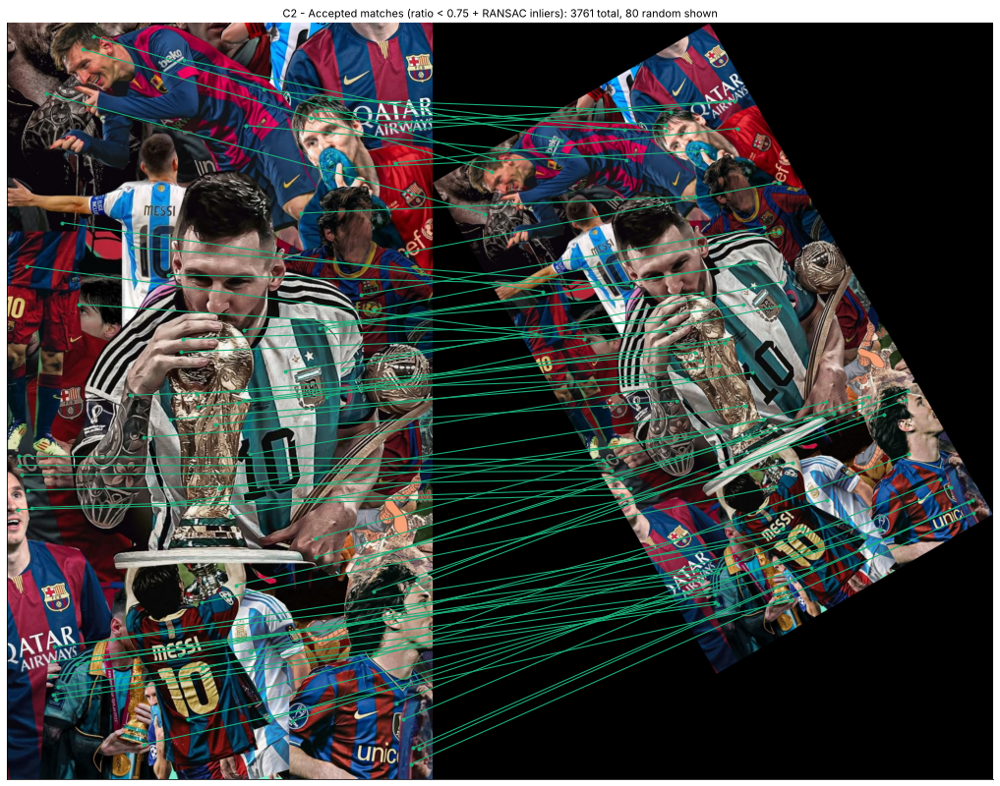

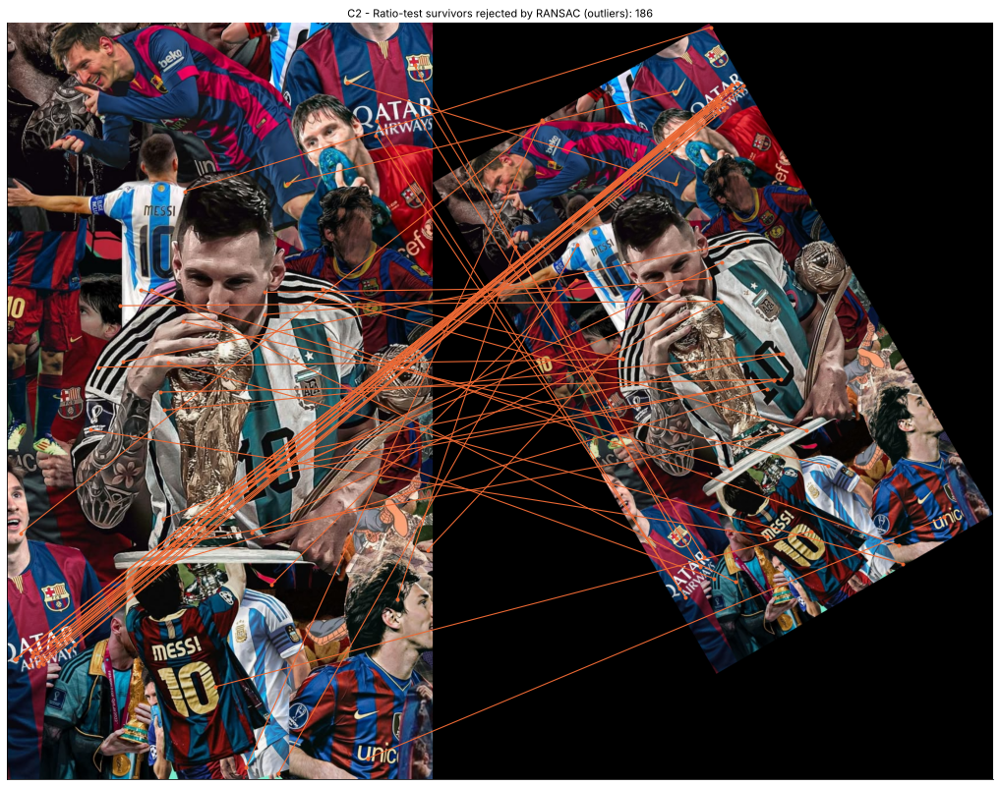

In [ ]:
# ---------------- C2: rotated + scaled copy, descriptor matching ----------------
def similarity_warp(img, angle, scale):
    """Rotate (deg, CCW) and scale about the centre; enlarge the canvas so nothing is cropped. Returns image and 2x3 M."""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    corners = M @ np.array([[0, 0, 1], [w, 0, 1], [0, h, 1], [w, h, 1]], float).T
    M[:, 2] -= corners.min(axis=1)
    W2, H2 = np.ceil(corners.max(axis=1) - corners.min(axis=1)).astype(int)
    return cv2.warpAffine(img, M, (int(W2), int(H2)), flags=cv2.INTER_LINEAR, borderValue=0), M

def match_sift(kpA, desA, kpB, desB, M_true, ratio=RATIO):
    bf = cv2.BFMatcher(cv2.NORM_L2)                              # Euclidean distance between 128-D descriptors
    knn = bf.knnMatch(desA, desB, k=2)
    nn = [m for m, n in knn]
    good = [m for m, n in knn if m.distance < ratio * n.distance]
    def correct(ms):
        if not ms: return np.zeros(0, bool)
        pa = np.float32([kpA[m.queryIdx].pt for m in ms]); pb = np.float32([kpB[m.trainIdx].pt for m in ms])
        proj = pa @ M_true[:, :2].T + M_true[:, 2]
        return np.linalg.norm(proj - pb, axis=1) < GT_TOL
    out = dict(nn=nn, good=good, nn_ok=correct(nn), good_ok=correct(good), inl=np.zeros(len(good), bool), A=None)
    if len(good) >= 3:
        pa = np.float32([kpA[m.queryIdx].pt for m in good]); pb = np.float32([kpB[m.trainIdx].pt for m in good])
        A, inl = cv2.estimateAffinePartial2D(pa, pb, method=cv2.RANSAC, ransacReprojThreshold=RANSAC_THR)
        out["A"], out["inl"] = A, (inl.ravel() > 0) if inl is not None else out["inl"]
    return out

rgb2, M = similarity_warp(rgb, TF_ANGLE, TF_SCALE)
gray2 = cv2.cvtColor(rgb2, cv2.COLOR_RGB2GRAY)
kp2, des2 = sift.detectAndCompute(gray2, None)
t0 = time.perf_counter(); R = match_sift(kp1, des1, kp2, des2, M); match_ms = 1000 * (time.perf_counter() - t0)

# matching-strategy comparison (same descriptors)
cc = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True).match(des1, des2)
pa = np.float32([kp1[m.queryIdx].pt for m in cc]); pb = np.float32([kp2[m.trainIdx].pt for m in cc])
cc_ok = np.linalg.norm(pa @ M[:, :2].T + M[:, 2] - pb, axis=1) < GT_TOL
A = R["A"]; est_scale = float(np.hypot(A[0, 0], A[0, 1])); est_angle = float(np.degrees(np.arctan2(A[0, 1], A[0, 0])))
inl_ok = R["good_ok"][R["inl"]]
EVID["c2"] = dict(kp1=len(kp1), kp2=len(kp2), nn=len(R["nn"]), nn_prec=R["nn_ok"].mean(), cc=len(cc), cc_prec=cc_ok.mean(),
                  good=len(R["good"]), good_prec=R["good_ok"].mean(), inl=int(R["inl"].sum()), inl_prec=inl_ok.mean(),
                  est_angle=est_angle, est_scale=est_scale, ms=match_ms, correct=int(R["good_ok"].sum()))

print(f"Transform           : rotate {TF_ANGLE} deg CCW, scale {TF_SCALE} -> new image {gray2.shape[1]}x{gray2.shape[0]} px")
print(f"Keypoints           : original {len(kp1):,}  |  transformed {len(kp2):,}")
print(f"Descriptors         : {des1.shape} and {des2.shape}, metric = Euclidean (L2)")
print_table(["matching strategy", "matches kept", "correct (<3px from truth)", "precision"],
            [["nearest neighbour only", len(R["nn"]), int(R["nn_ok"].sum()), R["nn_ok"].mean()],
             ["mutual NN (cross-check)", len(cc), int(cc_ok.sum()), cc_ok.mean()],
             [f"Lowe ratio test < {RATIO}", len(R["good"]), int(R["good_ok"].sum()), R["good_ok"].mean()],
             [f"ratio + RANSAC similarity ({RANSAC_THR}px)", int(R["inl"].sum()), int(inl_ok.sum()), inl_ok.mean()]],
            title="Matching strategies (ground truth from the known transform)")
print(f"RANSAC-estimated transform: rotation {est_angle:.2f} deg (true {TF_ANGLE}), scale {est_scale:.4f} (true {TF_SCALE})")
print(f"Matching time (kNN + ratio + RANSAC): {match_ms:.0f} ms")

def draw_matches(imA, imB, kA, kB, ms, colours, n_show=80, seed=0):
    hA, wA = imA.shape[:2]; hB, wB = imB.shape[:2]
    canvas = np.zeros((max(hA, hB), wA + wB, 3), np.uint8); canvas[:hA, :wA] = imA; canvas[:hB, wA:] = imB
    idx = np.random.default_rng(seed).permutation(len(ms))[:n_show]
    fig, ax = plt.subplots(figsize=(17, 11)); ax.imshow(canvas)
    for i in idx:
        (x1, y1), (x2, y2) = kA[ms[i].queryIdx].pt, kB[ms[i].trainIdx].pt
        ax.plot([x1, x2 + wA], [y1, y2], "-", color=colours[i], lw=1.1)
        ax.plot([x1, x2 + wA], [y1, y2], "o", color=colours[i], ms=3)
    ax.set_xticks([]); ax.set_yticks([])
    return fig, ax

acc = [m for m, k in zip(R["good"], R["inl"]) if k]
fig, ax = draw_matches(rgb, rgb2, kp1, kp2, acc, [C[2]] * len(acc), n_show=80)
ax.set_title(f"C2 - Accepted matches (ratio < {RATIO} + RANSAC inliers): {len(acc)} total, 80 random shown")
plt.show()
rej = [m for m, k in zip(R["good"], R["inl"]) if not k]
if rej:
    fig, ax = draw_matches(rgb, rgb2, kp1, kp2, rej, [C[1]] * len(rej), n_show=60, seed=1)
    ax.set_title(f"C2 - Ratio-test survivors rejected by RANSAC (outliers): {len(rej)}"); plt.show()

HOG cosine similarity between unrelated 128x128 windows: mean 0.632, 95th percentile 0.691


rotation (deg) | SIFT correct matches | SIFT matching score | SIFT precision | HOG cosine sim. | Canny repeatability F1
----------------+----------------------+---------------------+----------------+-----------------+------------------------
             0 |                9,469 |              1.0000 |         1.0000 |          1.0000 |                 1.0000
            15 |                5,936 |              0.6269 |         0.9778 |          0.7573 |                 0.9592
            30 |                6,053 |              0.6392 |         0.9782 |          0.7103 |                 0.9547
            45 |                6,022 |              0.6360 |         0.9779 |          0.7075 |                 0.9585
            60 |                5,987 |              0.6323 |         0.9779 |          0.6905 |                 0.9542
            90 |                8,812 |              0.9306 |         0.9957 |          0.7013 |                 0.9995
           135 |                5,993 

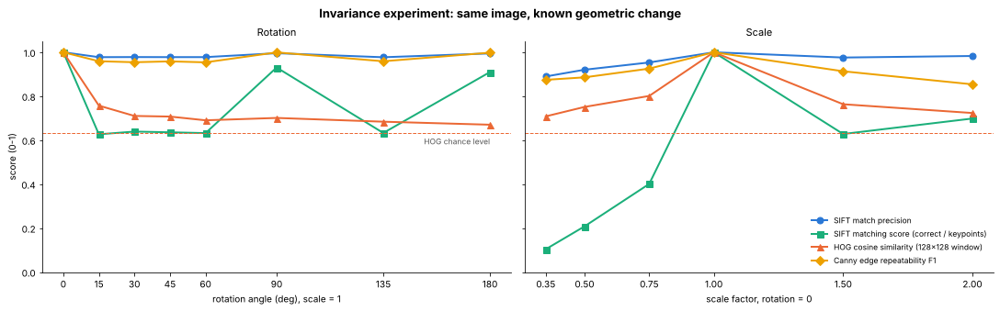

In [ ]:
# ---------------- Robustness sweep: SIFT vs HOG vs Canny under rotation and scale ----------------
WIN = 128
def centre_window(img, centre, size=WIN):
    x, y = int(round(centre[0] - size / 2)), int(round(centre[1] - size / 2))
    return img[y:y + size, x:x + size]

c0 = (W / 2, H / 2)
hog_ref = hog(centre_window(gray, c0))["feat"]
# chance level: cosine similarity between the centre window and 200 random UNRELATED windows of the same image
rs = np.random.default_rng(SEED)
base = []
while len(base) < 200:
    cx_, cy_ = rs.uniform(WIN / 2, W - WIN / 2), rs.uniform(WIN / 2, H - WIN / 2)
    if abs(cx_ - c0[0]) > WIN or abs(cy_ - c0[1]) > WIN:
        base.append(cos(hog_ref, hog(centre_window(gray, (cx_, cy_)))["feat"]))
hog_chance = float(np.mean(base)); EVID["hog_chance"] = (hog_chance, float(np.percentile(base, 95)))
print(f"HOG cosine similarity between unrelated {WIN}x{WIN} windows: mean {hog_chance:.3f}, 95th percentile {np.percentile(base, 95):.3f}")
canny0 = canny(blur, *REF_PAIR)

def evaluate(angle, scale):
    g2, M_ = similarity_warp(gray, angle, scale)
    k2, d2 = sift.detectAndCompute(g2, None)
    r = match_sift(kp1, des1, k2, d2, M_)
    c_new = M_[:, :2] @ np.array(c0) + M_[:, 2]
    hog_sim = cos(hog_ref, hog(centre_window(g2, c_new))["feat"])
    warped_edges = (cv2.warpAffine(canny0.astype(np.float32), M_, (g2.shape[1], g2.shape[0])) > 64).astype(np.uint8)
    edges_new = canny(cv2.GaussianBlur(g2, GAUSS_KSIZE, GAUSS_SIGMA), *REF_PAIR)
    valid = cv2.warpAffine(np.ones_like(gray), M_, (g2.shape[1], g2.shape[0])) > 0   # ignore canvas border
    valid = cv2.erode(valid.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0
    _, _, f1 = tolerant_f1(warped_edges * valid, (edges_new > 0) * valid, tol=2)
    return dict(score=r["good_ok"].sum() / len(kp1), prec=r["good_ok"].mean() if len(r["good"]) else 0.0,
                n_ok=int(r["good_ok"].sum()), hog=hog_sim, canny_f1=f1)

angles = [0, 15, 30, 45, 60, 90, 135, 180]
scales = [0.35, 0.5, 0.75, 1.0, 1.5, 2.0]
rot_res = [evaluate(a, 1.0) for a in angles]
sc_res  = [evaluate(0, s) for s in scales]
EVID["sweep_rot"] = dict(zip(angles, rot_res)); EVID["sweep_sc"] = dict(zip(scales, sc_res))

print_table(["rotation (deg)", "SIFT correct matches", "SIFT matching score", "SIFT precision", "HOG cosine sim.", "Canny repeatability F1"],
            [[a, r["n_ok"], r["score"], r["prec"], r["hog"], r["canny_f1"]] for a, r in zip(angles, rot_res)])
print_table(["scale", "SIFT correct matches", "SIFT matching score", "SIFT precision", "HOG cosine sim.", "Canny repeatability F1"],
            [[s, r["n_ok"], r["score"], r["prec"], r["hog"], r["canny_f1"]] for s, r in zip(scales, sc_res)])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for a_, xs_, res, xl in [(ax[0], angles, rot_res, "rotation angle (deg), scale = 1"), (ax[1], scales, sc_res, "scale factor, rotation = 0")]:
    a_.plot(xs_, [r["prec"] for r in res], "o-", color=C[0], label="SIFT match precision")
    a_.plot(xs_, [r["score"] for r in res], "s-", color=C[2], label="SIFT matching score (correct / keypoints)")
    a_.plot(xs_, [r["hog"] for r in res], "^-", color=C[1], label=f"HOG cosine similarity ({WIN}x{WIN} window)")
    a_.plot(xs_, [r["canny_f1"] for r in res], "D-", color=C[3], label="Canny edge repeatability F1")
    a_.set(xlabel=xl, ylim=(0, 1.05)); a_.set_xticks(xs_)
for a_ in ax: a_.axhline(hog_chance, color=C[1], lw=1, ls="--")
ax[0].text(angles[-1], hog_chance - 0.05, "HOG chance level", color="#555", ha="right", fontsize=8.5)
ax[0].set_ylabel("score (0-1)"); ax[0].set_title("Rotation"); ax[1].set_title("Scale")
ax[1].legend(loc="lower right", fontsize=8.5)
fig.suptitle("Invariance experiment: same image, known geometric change"); plt.show()

**C2 result.** 9,469 keypoints in the original, 6,055 in the 0.75-scaled copy (fewer pixels means fewer fine-scale points).

| Strategy | Kept | Correct | Precision |
|---|---|---|---|
| nearest neighbour only | 9,469 | 3,991 | 42.2 % |
| mutual cross-check | 4,337 | 3,834 | 88.4 % |
| ratio test < 0.75 | 3,947 | 3,761 | 95.3 % |
| **ratio + RANSAC** | **3,761** | **3,761** | **100 %** |

The ratio test raises precision from 42 % to 95 % while keeping 94 % of the correct matches (3,761 of 3,991). RANSAC then removes exactly the 186 remaining wrong matches. The recovered transform is **30.00° / 0.7500** against a true **30° / 0.75**. Brute-force matching costs $O(N_1N_2\cdot128)$ and took about 0.7 s; a FLANN k-d tree would be the choice for larger sets.

**Rotation/scale sweep (also used in Part D).** Each transform is applied to the same image, and the same quantities are measured for all three methods.
* **SIFT:** precision stays **≥ 97.7 % at every rotation** and **≥ 89 % from scale 0.35 to 2.0**. The *number* of correct matches varies: rotations that are not multiples of 90° need interpolation, which changes fine detail (63 % of keypoints matched versus 91–93 % at 90°/180°), and at scale 0.35 only 10 % match because the finest-scale keypoints no longer exist.
* **HOG** (fixed 128×128 window at the corresponding centre): cosine similarity drops to **0.76 at only 15°** and to 0.67–0.70 beyond. The chance level — similarity to *unrelated* windows of the same image — is **0.63** (95th percentile 0.69), so a rotated HOG window is about as similar as a random one.
* **Canny:** edge repeatability F1 ≥ 0.95 under rotation (the L2 gradient magnitude is isotropic, so the edges simply rotate with the image), but 0.85–0.87 at scales 2.0 and 0.35, because a fixed σ and fixed thresholds are tuned to one scale. Canny also produces no descriptors, so it cannot say which edge corresponds to which.

## C3. Why SIFT is robust to scale and rotation — and when it fails (1)

**Scale.** Keypoints are detected as extrema across the whole scale space. A point's *characteristic scale* σ is where the scale-normalised DoG peaks. If the image is scaled by $s$, the same structure peaks at $s\sigma$, and because the descriptor window is sized in proportion to σ, the **same physical content** is described at any zoom level.

**Rotation.** Every keypoint receives a dominant orientation from its local gradients, and the descriptor's gradient directions are measured *relative to it* (the window is rotated into this frame). A rotation of the image shifts the dominant orientation by the same angle, so the two cancel.

**Additionally:** gradients are unaffected by brightness offsets, normalisation removes contrast changes, and Gaussian weighting with interpolated votes tolerates small localisation errors.

**One reason it fails — repeated patterns.** The ratio test assumes the correct match is *unique*. In this collage, "QATAR AIRWAYS" appears twice, several club crests and the "MESSI 10" shirt repeat, and the descriptors of these copies are almost identical. Below, every keypoint is compared with the others **in the same image** to find those with a near-identical twin more than 40 px away.

Keypoints with a near-identical descriptor >40 px away in the SAME image: 512 (5.4%)
Effect of self-similarity on matching to the rotated/scaled copy
keypoint group               | count | plain-NN match correct | pass ratio test | precision after ratio test
------------------------------+-------+------------------------+-----------------+----------------------------
repeated-pattern (ambiguous) |   512 |                 0.2988 |          0.3555 |                     0.5989
                 distinctive | 8,957 |                 0.4285 |          0.4203 |                     0.9700



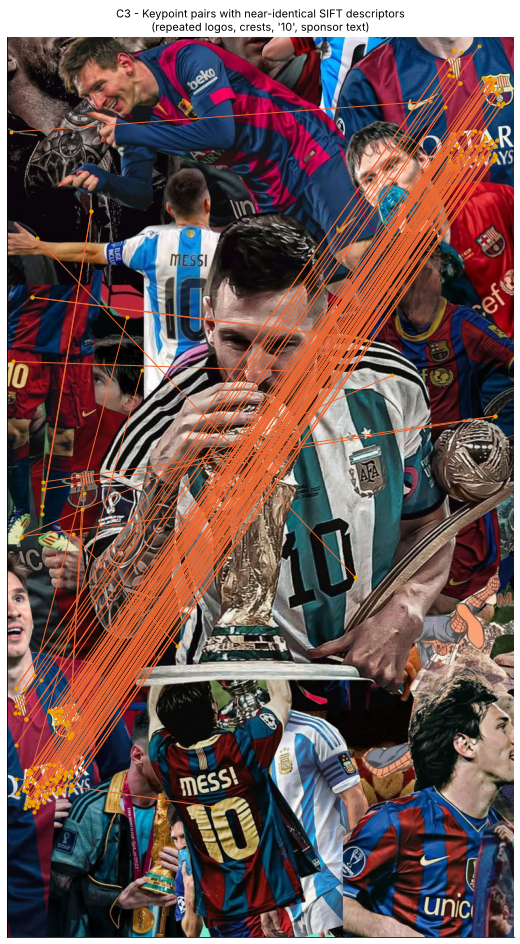

In [ ]:
# ---------------- C3: a failure mode - repeated patterns make descriptors ambiguous ----------------
bf = cv2.BFMatcher(cv2.NORM_L2)
self_knn = bf.knnMatch(des1, des1, k=2)          # neighbour 0 is the keypoint itself
pts = np.float32([k.pt for k in kp1])
dup = []
for m in self_knn:
    if len(m) < 2: continue
    o = m[1]
    far = np.linalg.norm(pts[o.queryIdx] - pts[o.trainIdx]) > 40
    if far and o.distance < 0.5 * np.median([mm[1].distance for mm in self_knn[:2000] if len(mm) > 1]):
        dup.append(o)
dup_ids = {d.queryIdx for d in dup}
is_dup = np.array([m.queryIdx in dup_ids for m in R["nn"]])
good_q = {g.queryIdx for g in R["good"]}
passed = np.array([m.queryIdx in good_q for m in R["nn"]])
good_ok_q = {g.queryIdx: ok for g, ok in zip(R["good"], R["good_ok"])}
prec_dup = np.mean([good_ok_q[q] for q in good_ok_q if q in dup_ids]) if any(q in dup_ids for q in good_ok_q) else float("nan")
prec_uni = np.mean([good_ok_q[q] for q in good_ok_q if q not in dup_ids])
EVID["c3"] = dict(prec_dup=prec_dup, prec_uni=prec_uni, n_dup=len(dup_ids), frac=len(dup_ids) / len(kp1),
                  pass_dup=passed[is_dup].mean(), pass_uni=passed[~is_dup].mean(),
                  nnprec_dup=R["nn_ok"][is_dup].mean(), nnprec_uni=R["nn_ok"][~is_dup].mean())
print(f"Keypoints with a near-identical descriptor >40 px away in the SAME image: {len(dup_ids)} ({len(dup_ids)/len(kp1):.1%})")
print_table(["keypoint group", "count", "plain-NN match correct", "pass ratio test", "precision after ratio test"],
            [["repeated-pattern (ambiguous)", int(is_dup.sum()), R["nn_ok"][is_dup].mean(), passed[is_dup].mean(), prec_dup],
             ["distinctive", int((~is_dup).sum()), R["nn_ok"][~is_dup].mean(), passed[~is_dup].mean(), prec_uni]],
            title="Effect of self-similarity on matching to the rotated/scaled copy")

fig, ax = plt.subplots(figsize=(8, 13)); ax.imshow(rgb)
for d in dup[:120]:
    (x1, y1), (x2, y2) = kp1[d.queryIdx].pt, kp1[d.trainIdx].pt
    ax.plot([x1, x2], [y1, y2], "-", color=C[1], lw=1); ax.plot([x1, x2], [y1, y2], "o", color=C[3], ms=3)
ax.set_title("C3 - Keypoint pairs with near-identical SIFT descriptors\n(repeated logos, crests, '10', sponsor text)")
ax.set_xticks([]); ax.set_yticks([]); plt.show()

**C3 result.** **512 keypoints (5.4 %)** have a near-duplicate elsewhere in the image; the plot shows them pairing the two "QATAR AIRWAYS" logos and the repeated crests. When matching to the transformed copy:

| Keypoint group | Plain NN correct | Pass ratio test | Precision after ratio test |
|---|---|---|---|
| repeated-pattern | 29.9 % | 35.6 % | **59.9 %** |
| distinctive | 42.9 % | 42.0 % | **97.0 %** |

For repeated structures, the nearest neighbour is often the *other copy*. The ratio test cannot separate two identical candidates, so these points are either rejected (lost) or accepted wrongly (40 % of the time). SIFT describes appearance *locally*, so it cannot tell identical copies apart without global geometry such as RANSAC.

Other failure causes: **large downscaling** (scale 0.35 → only 10 % of keypoints matched, because 69 % of them lived at the finest scale), out-of-plane viewpoint change beyond about 40° (SIFT is invariant to similarity transforms, not perspective), motion blur, non-rigid deformation, and textureless regions.

---
# Part D — Comparative Analysis and Engineering Judgment

## D1. Comparison table (2)
The cost of each method is first measured on the same machine (median of repeated runs).

In [ ]:
# ---------------- D1: measured computational characteristics ----------------
def timeit(fn, n=5):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); out = fn(); ts.append(time.perf_counter() - t0)
    return 1000 * np.median(ts), out

t_canny, e = timeit(lambda: canny(cv2.GaussianBlur(gray, GAUSS_KSIZE, GAUSS_SIGMA), *REF_PAIR))
t_hog_np, hh = timeit(lambda: hog(roi)["feat"])
t_hog_cv, hc = timeit(lambda: cv_hog.compute(roi))
t_hog_full, hf = timeit(lambda: cv2.HOGDescriptor((W // 8 * 8, H // 8 * 8), (16, 16), (8, 8), (8, 8), 9).compute(gray[:H // 8 * 8, :W // 8 * 8]), n=3)
t_sift, (k_, d_) = timeit(lambda: sift.detectAndCompute(gray, None), n=3)
EVID["d1"] = dict(t_canny=t_canny, t_hog_np=t_hog_np, t_hog_cv=t_hog_cv, t_hog_full=t_hog_full, t_sift=t_sift,
                  hog_full_dim=hf.size)
print_table(["method", "input", "output", "output size", "median time (ms)"],
            [["Gaussian + Canny", f"{W}x{H} gray", "binary edge map", f"{W}x{H} = {W*H:,} px ({(e>0).sum():,} edges)", t_canny],
             ["HOG (our NumPy code)", f"{rw}x{rh} ROI", "dense vector", f"{hh.size:,}-D", t_hog_np],
             ["HOG (OpenCV)", f"{rw}x{rh} ROI", "dense vector", f"{hc.size:,}-D", t_hog_cv],
             ["HOG (OpenCV)", f"{W//8*8}x{H//8*8} full image", "dense vector", f"{hf.size:,}-D", t_hog_full],
             ["SIFT detect + describe", f"{W}x{H} gray", "keypoints + descriptors", f"{len(k_):,} x 128", t_sift]],
            title="Measured cost on this machine (median of repeated runs)")

Measured cost on this machine (median of repeated runs)
method                 | input               | output                  | output size                          | median time (ms)
------------------------+---------------------+-------------------------+--------------------------------------+------------------
      Gaussian + Canny |       736x1308 gray |         binary edge map | 736x1308 = 962,688 px (85,971 edges) |           5.0345
  HOG (our NumPy code) |         512x640 ROI |            dense vector |                            179,172-D |            18.94
          HOG (OpenCV) |         512x640 ROI |            dense vector |                            179,172-D |           5.6700
          HOG (OpenCV) | 736x1304 full image |            dense vector |                            530,712-D |            18.77
SIFT detect + describe |       736x1308 gray | keypoints + descriptors |                          9,469 x 128 |           280.16



| | **Canny** | **HOG** | **SIFT** |
|---|---|---|---|
| **Output** | Binary edge map, same size as the image, 1-px edges (here 85,971 edge pixels in 736 × 1308) | One dense, *fixed-length* vector per window (179,172-D for the 512 × 640 ROI) | A *variable* set of keypoints $(x, y, \sigma, \theta)$, each with a 128-D descriptor (here 9,469 × 128) |
| **Principal purpose** | *Locate* boundaries: where intensity changes sharply | *Describe* the shape / gradient layout of a known window, for classification and detection (e.g. HOG + SVM people detector) | *Find and match* distinctive points across images: registration, stitching, recognition, 3-D reconstruction |
| **Noise** | Low after Gaussian smoothing (false edges 0.95 % at noise σ = 20); without smoothing 47.5 % fragments | Moderate: cell pooling averages noise; tiny cells (4 px) become noisy | Strong points robust; noise adds small, unstable fine-scale keypoints |
| **Illumination** | Absolute thresholds: lower contrast loses edges; uneven lighting needs different thresholds per region | Invariant to linear contrast/brightness (cosine 1.000); near-invariant to gamma (0.992) | Invariant to affine brightness/contrast (normalised gradient histograms) |
| **Rotation** | Detection is rotation-*covariant* (F1 ≥ 0.95), but the output is not a descriptor | **Not invariant**: cosine 0.76 at 15°, chance level 0.63 | **Invariant**: precision ≥ 97.7 % at all angles tested |
| **Scale** | Fixed σ and thresholds: F1 0.85 at 2× | **Not invariant**: fixed window and cell size | **Invariant** over about 0.5–2× (precision ≥ 92 %); degrades at 0.35× |
| **Texture / repetition** | Low thresholds flood the map with texture (15.3 % density) | Encodes texture as gradient energy | Repeated patterns give ambiguous matches (precision 59.9 %) |
| **Computation** | Local 3×3 filters + NMS + linear-time hysteresis, $O(N)$: **4.6 ms** | One pass, $O(N)$, fixed cost; **5.8 ms** (OpenCV, ROI), 18 ms full image | Gaussian pyramid of about 6 octaves × 6 levels + per-keypoint descriptors: **242 ms**; brute-force matching $O(N_1N_2)$: about 720 ms |
| **Key parameters** | σ, low/high thresholds, aperture | cell, block, bins, normalisation | octave layers, contrast/edge thresholds, σ, ratio |

## D2. Recommendations, backed by the experiments (2)

**(i) Extracting object boundaries → Gaussian smoothing (σ ≈ 1.4) + Canny, thresholds ≈ 1:3 (50/150), `L2gradient=True`.**
*Evidence:* Canny gave the thinnest edges (**1.05 px** vs Sobel's 2.63) and the most continuous ones (**6.6 %** fragments, mean component 86 px, vs 48.5 % for Sobel and 78.4 % for LoG). Under noise it added only **0.95 %** false edges versus **18.6 %** for LoG, and it is the cheapest method (4.6 ms). Smoothing was essential: fragments fell from 47.5 % to 6.6 %. The threshold sweep shows (20, 60) floods the result with texture (15.3 %) and (150, 300) breaks outlines (3.3 %). For heavily textured scenes, raise σ to about 2 (density 7.8 % → 4.4 %) rather than raising the thresholds, because smoothing removes texture before it can seed contours.

**(ii) Representing shape / local gradient structure → HOG (8-px cells, 9 unsigned bins, 2×2 blocks, L2-Hys) on an aligned window.**
*Evidence:* the visualisation captures the face outline, fingers, stripes and trophy as oriented strokes. Block normalisation made the descriptor identical under linear contrast change (cosine 1.000) and nearly so under gamma (0.992). 8 px / 9 bins gives 179 k dimensions, against 727 k for 4-px cells, with little practical gain in detail. *Caveat:* HOG fell to chance similarity after a 15° rotation, so it should be used on windows that are already aligned (sliding-window or multi-scale detection), never for matching across arbitrary transforms. In a combined system, Canny can locate candidate object regions, and HOG then describes their shape.

**(iii) Matching distinctive local features across transformed images → SIFT + L2 k-NN (k = 2) + Lowe ratio 0.75 + RANSAC geometric verification.**
*Evidence:* for a 30° rotation plus 0.75 scaling, all 3,761 accepted matches were correct (**100 %**), and the transform was recovered as **30.00° / 0.7500**. Precision stayed ≥ 97.7 % at every rotation and ≥ 89 % from 0.35× to 2×, where HOG dropped to chance and Canny offers no correspondences. *Caveat:* in repetitive scenes (logos, crests) the ratio test alone reached only 59.9 % precision, so the RANSAC stage is **required**, not optional. For large databases, replace brute force with FLANN.

**Overall pipeline:** Canny for *where the structure is*, HOG for *what shape it has* in a fixed frame, SIFT for *which point corresponds to which* across viewpoints.

---
## Examiner quick reference — change a parameter, predict the effect

| Change | Predicted effect | Why (mathematics) | Measured here |
|---|---|---|---|
| Gaussian σ ↑ (1.4 → 3) | Fewer, smoother edges; corners rounded; fine detail lost | Step-edge gradient peak ∝ $h/\sigma$; more high frequencies removed | density 7.8 % → 1.7 % |
| No smoothing | Many short spurious edges | Derivative ∝ $\omega$ amplifies noise | fragments 6.6 % → 47.5 % |
| Canny high ↑ | Whole weak contours vanish | Fewer strong seeds for hysteresis | 12.8 % → 2.6 % (60 → 400) |
| Canny low ↓ | Contours extend further, texture leaks in | More weak pixels connected to seeds | 5.8 % → 10.0 % (140 → 10) |
| `L2gradient=False` | Slightly more diagonal edges | $\lvert g_x\rvert+\lvert g_y\rvert$ overestimates diagonal magnitude by up to $\sqrt2$ | — |
| Sobel aperture 3 → 5 | Larger magnitudes, smoother derivative; same thresholds then pass more pixels | 5×5 kernel has larger weights and more built-in smoothing | — |
| HOG cell 8 → 4 | 4× dimensions, finer but noisier | $D\propto 1/c^2$ | 179,172 → 726,948 |
| HOG bins 9 → 18 | 2× dimensions, 10° resolution | $D\propto n$ | 179,172 → 358,344 |
| Signed gradients (0–360°) | Polarity kept; 18 bins needed for 20° resolution | θ no longer taken mod 180° | — |
| No block normalisation | Descriptor scales with contrast | No division by $\lVert v\rVert$ | raw histogram scale = 0.50 at 0.5× contrast |
| SIFT `contrastThreshold` ↑ | Fewer keypoints, mostly lost in dark/flat areas | Rejects small $\lvert D\rvert$ | — |
| SIFT `edgeThreshold` ↓ | More edge-like points rejected | Stricter Hessian ratio test | — |
| Ratio 0.75 → 0.6 / 0.9 | Fewer but more precise matches / more matches, more outliers | Stricter / looser uniqueness test | — |

## Evidence summary (live values from this run)

In [ ]:
# ---------------- Evidence summary (all numbers used in the written answers) ----------------
nk = f"Canny {REF_PAIR}"
print("A1  noise sigma raw -> smoothed           :", f"{EVID['ns_raw']:.2f} -> {EVID['ns_blur']:.2f}")
print("A1  Canny fragments <10px raw -> smoothed :", f"{EVID['a1_raw']['short_frac']:.1%} -> {EVID['a1_blur']['short_frac']:.1%}")
print("A3  thickness Sobel / LoG / Canny          :", " / ".join(f"{EVID['a3_clean'][k]['thickness']:.2f}" for k in EVID['a3_clean']))
print("A3  false-edge rate Sobel / LoG / Canny    :", " / ".join(f"{EVID['a3_noise'][k]['spurious']:.2%}" for k in EVID['a3_noise']))
print("A4  densities                               :", {k: round(v, 4) for k, v in EVID['a4_pairs'].items()})
print("B1  HOG dims                                :", EVID['b1']['D'])
print("C1  SIFT keypoints, descriptor shape        :", EVID['c1']['n'], EVID['c1']['shape'])
print("C2  ratio-test precision / RANSAC precision :", f"{EVID['c2']['good_prec']:.3f} / {EVID['c2']['inl_prec']:.3f}")
print("C2  estimated angle / scale                 :", f"{EVID['c2']['est_angle']:.2f} / {EVID['c2']['est_scale']:.4f}")
print("Sweep HOG cos @45deg, SIFT prec @45deg      :", f"{EVID['sweep_rot'][45]['hog']:.3f}, {EVID['sweep_rot'][45]['prec']:.3f}")

A1  noise sigma raw -> smoothed           : 2.94 -> 0.35
A1  Canny fragments <10px raw -> smoothed : 47.5% -> 6.6%
A3  thickness Sobel / LoG / Canny          : 2.63 / 1.03 / 1.05
A3  false-edge rate Sobel / LoG / Canny    : 0.12% / 18.64% / 0.95%
A4  densities                               : {(20, 60): 0.1532, (50, 150): 0.0893, (100, 200): 0.0604, (150, 300): 0.0325}
B1  HOG dims                                : 179172
C1  SIFT keypoints, descriptor shape        : 9469 (9469, 128)
C2  ratio-test precision / RANSAC precision : 0.953 / 1.000
C2  estimated angle / scale                 : 30.00 / 0.7500
Sweep HOG cos @45deg, SIFT prec @45deg      : 0.707, 0.978
